# Analyse de la Base de Données Installations des Produits CNI

## I. Exploration et Nettoyage des données :

## 1. Compréhension des données

### 1.1 Importation des librairies

In [1162]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [ ]:
df_kpi = pd.read_csv("base_de_données_installations_produits_CNI_2.csv", delimiter=";", encoding="cp1252")

In [ ]:
df_kpi["date_installation"].isna().sum()

np.int64(0)

In [1165]:
"""import numpy as np
import pandas as pd

def generate_dataset_with_full_relations(df):

    df = df.copy()

    # =========================
    # 0. PREPROCESS MINIMAL (juste pour calculs internes)
    # =========================
    debit = pd.to_numeric(df["Debit_reseau_Mbps"], errors='coerce').fillna(10)

    # =========================
    # 1. NOMBRE ESSAIS (variable pivot)
    # =========================
    score_essais = (
        +0.5 * (df["Nom_produit"] == "MAKATIB").astype(int)
        +0.4 * df["version_produit"].isin([3.0, 2.0, 1.0])
        +0.6 * df["Gouvernorat"].isin(["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"]).astype(int)
        +0.7 * df["Systeme_exploitation_poste"].isin(["WindowsXP","Unknown"]).astype(int)
        +1.2 * df["Remarques"].isin(["problème réseau","erreur configuration poste", "version incompatible","connexion serveur lente" ]).astype(int)
        -0.8 * (debit > 20).astype(int)
        +0.3 * (df["Mode_installation"] == "Telemaintenance").astype(int)
        +1.5 * (df["Duree_installation_minutes"] > 120).astype(int)
        +1.5 * (df["client_a_reclame"] == "oui").astype(int)
        +1.5 * (df["nombre_reclamations_client"] >= 1).astype(int)
        -0.4 * (df["client_satisfait"] == "oui").astype(int)
        + np.random.normal(0,1,len(df))
    )

    df["nombre_essais_installation"] = np.clip(
        np.round(2 + score_essais), 1, 5
    )

    # =========================
    # 2. DUREE INSTALLATION
    # =========================
    duree = (
        60
        + 40 * (df["Nom_produit"] == "MAKATIB").astype(int)
        + 10 * df["version_produit"].isin([3.0, 2.0, 1.0])
        +  * df["Gouvernorat"].isin(["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"]).astype(int)
        + 50 * df["Systeme_exploitation_poste"].isin(["WindowsXP","Unknown"]).astype(int)
        + 20 * df["Remarques"].isin(["problème réseau","erreur configuration poste", "version incompatible","connexion serveur lente" ]).astype(int)
        - 60 * (debit > 20).astype(int)
        + 20 * (df["Mode_installation"] == "Telemaintenance").astype(int)
        + 30 * (df["nombre_essais_installation"] >= 3).astype(int)
        + 25 * (df["client_a_reclame"] == "oui").astype(int)
        + 10 * (df["nombre_reclamations_client"] >= 1).astype(int)
        + np.random.normal(0, 20, len(df))
    )

    df["Duree_installation_minutes"] = np.clip(duree, 5, None)

    # =========================
    # 3. INSTALLATION REUSSIE
    # =========================
    score_success = (
        +0.1 * (df["Nom_produit"] == "INSAF").astype(int)
        +0.2 * df["version_produit"].isin([1.2, 2.1, 2.2])
        + 0.05 * (~df["Gouvernorat"].isin(["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"])).astype(int)        +1.2 * (debit > 20).astype(int)
        -0.5 * (df["Taille_site_postes"] > 20).astype(int)
        +1.5 * df["Systeme_exploitation_poste"].isin(["Win7","Windows server 2019","Windows server 2022"]).astype(int)
        -2.0 * (df["nombre_essais_installation"] >= 3).astype(int)
        -1.2 * (df["client_a_reclame"] == "oui").astype(int)
        -1.0 * (df["nombre_reclamations_client"] >= 1).astype(int)
        +2.0 * (df["client_satisfait"] == "oui").astype(int)
        +0.5 * (df["Mode_installation"] == "Sur site").astype(int)
        -1.0 * (df["Duree_installation_minutes"] > 120).astype(int)
        + np.random.normal(0,1,len(df))
    )

    prob_success = 1/(1+np.exp(-score_success))

    df["installation_reussie"] = np.where(
        np.random.rand(len(df)) < prob_success, "oui", "non"
    )

    # =========================
    # 4. CLIENT SATISFAIT
    # =========================
    score_sat = (
        +0.1 * (df["Nom_produit"] == "INSAF").astype(int)
        +0.1 * df["version_produit"].isin([1.2, 2.1, 2.2])
        -1.5 * df["Remarques"].notna().astype(int)
        +0.5 * (debit > 20).astype(int)
        +0.2 * (df["Mode_installation"] == "Sur site").astype(int)
        -1.5 * (df["nombre_essais_installation"] >= 3).astype(int)
        -1.2 * (df["Duree_installation_minutes"] > 120).astype(int)
        +2.5 * (df["installation_reussie"] == "oui").astype(int)
        -2.5 * (df["client_a_reclame"] == "oui").astype(int)
        -2.0 * (df["nombre_reclamations_client"] >= 1).astype(int)
        + np.random.normal(0,1,len(df))
    )

    prob_sat = 1/(1+np.exp(-score_sat))

    df["client_satisfait"] = np.where(
        np.random.rand(len(df)) < prob_sat, "oui", "non"
    )

    # =========================
    # 5. CLIENT A RECLAME
    # =========================
    score_reclame = (
        +0.1 * (df["Nom_produit"] == "MAKATIB").astype(int)
        +0.3 * df["version_produit"].isin([3.0, 2.0, 1.0])
        +0.7 * df["Systeme_exploitation_poste"].isin(["WindowsXP","Unknown"]).astype(int)
        +2.5 * df["Remarques"].notna().astype(int)
        +0.5 * (debit > 20).astype(int)
        +2.0 * (df["nombre_essais_installation"] >= 3).astype(int)
        +1.5 * (df["Duree_installation_minutes"] > 120).astype(int)
        -2.5 * (df["installation_reussie"] == "oui").astype(int)
        +2.5 * (df["nombre_reclamations_client"] >= 1).astype(int)
        -2.5 * (df["client_satisfait"] == "oui").astype(int)
        + np.random.normal(0,1,len(df))
    )

    prob_rec = 1/(1+np.exp(-score_reclame))

    df["client_a_reclame"] = np.where(
        np.random.rand(len(df)) < prob_rec, "oui", "non"
    )
    return df"""

'import numpy as np\nimport pandas as pd\n\ndef generate_dataset_with_full_relations(df):\n\n    df = df.copy()\n\n    # =========================\n    # 0. PREPROCESS MINIMAL (juste pour calculs internes)\n    # =========================\n    debit = pd.to_numeric(df["Debit_reseau_Mbps"], errors=\'coerce\').fillna(10)\n\n    # =========================\n    # 1. NOMBRE ESSAIS (variable pivot)\n    # =========================\n    score_essais = (\n        +0.5 * (df["Nom_produit"] == "MAKATIB").astype(int)\n        +0.4 * df["version_produit"].isin([3.0, 2.0, 1.0])\n        +0.6 * df["Gouvernorat"].isin(["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"]).astype(int)\n        +0.7 * df["Systeme_exploitation_poste"].isin(["WindowsXP","Unknown"]).astype(int)\n        +1.2 * df["Remarques"].isin(["problème réseau","erreur configuration poste", "version incompatible","connexion serveur lente" ]).astype(int)\n        -0.8 * (debit > 20).astype(int)\n        +0.3 * (df["Mode_install

In [1166]:
"""import random

def generer_plusieurs_lignes_bruit(df, n=200, proba_anomalie=0.5):
    lignes = []

    for _ in range(n):
        ligne = df.sample(1).iloc[0].copy()

        if random.random() < proba_anomalie:
            ligne["installation_reussie"] = np.nan

        if random.random() < proba_anomalie:
            ligne["Id_Client"] = np.nan

        if random.random() < proba_anomalie:
            ligne["Remarques"] = np.nan

        if random.random() < proba_anomalie:
            ligne["Systeme_exploitation_poste"] = random.choice(
                ["win10", "Win 10", "Win10", "Unknown"]
            )

        if random.random() < proba_anomalie:
            ligne["nombre_reclamations_client"] = random.choice([-2, 25])

        if random.random() < proba_anomalie:
            ligne["Version_precedente"] = "aucune"

        # IMPORTANT (manquait chez toi)
        lignes.append(ligne)

    return pd.DataFrame(lignes)"""

'import random\n\ndef generer_plusieurs_lignes_bruit(df, n=200, proba_anomalie=0.5):\n    lignes = []\n\n    for _ in range(n):\n        ligne = df.sample(1).iloc[0].copy()\n\n        if random.random() < proba_anomalie:\n            ligne["installation_reussie"] = np.nan\n\n        if random.random() < proba_anomalie:\n            ligne["Id_Client"] = np.nan\n\n        if random.random() < proba_anomalie:\n            ligne["Remarques"] = np.nan\n\n        if random.random() < proba_anomalie:\n            ligne["Systeme_exploitation_poste"] = random.choice(\n                ["win10", "Win 10", "Win10", "Unknown"]\n            )\n\n        if random.random() < proba_anomalie:\n            ligne["nombre_reclamations_client"] = random.choice([-2, 25])\n\n        if random.random() < proba_anomalie:\n            ligne["Version_precedente"] = "aucune"\n\n        # IMPORTANT (manquait chez toi)\n        lignes.append(ligne)\n\n    return pd.DataFrame(lignes)'

In [1167]:
"""def remove_outliers_iqr(df, col):
    df = df.copy()

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

    return df"""

'def remove_outliers_iqr(df, col):\n    df = df.copy()\n\n    Q1 = df[col].quantile(0.25)\n    Q3 = df[col].quantile(0.75)\n    IQR = Q3 - Q1\n\n    lower = Q1 - 1.5 * IQR\n    upper = Q3 + 1.5 * IQR\n\n    df[col] = df[col].clip(lower, upper)\n\n    return df'

In [1168]:
"""def fix_ranges(df):
    df = df.copy()

    # duration cannot be negative
    df["Duree_installation_minutes"] = df["Duree_installation_minutes"].clip(lower=1)

    # remove extreme high values
    df["Duree_installation_minutes"] = df["Duree_installation_minutes"].clip(upper=230)

    return df"""

'def fix_ranges(df):\n    df = df.copy()\n\n    # duration cannot be negative\n    df["Duree_installation_minutes"] = df["Duree_installation_minutes"].clip(lower=1)\n\n    # remove extreme high values\n    df["Duree_installation_minutes"] = df["Duree_installation_minutes"].clip(upper=230)\n\n    return df'

In [ ]:
"""df = generate_dataset_with_full_relations(df_kpi)

df_bruit = generer_plusieurs_lignes_bruit(df, n=200)

df = pd.concat([df, df_bruit], ignore_index=True)

# STEP 1: fix impossible values
df = fix_ranges(df)

# STEP 2: remove statistical outliers
df = remove_outliers_iqr(df, "Duree_installation_minutes")"""

'df = generate_dataset_with_full_relations(df1)\n\ndf_bruit = generer_plusieurs_lignes_bruit(df, n=200)\n\ndf = pd.concat([df, df_bruit], ignore_index=True)\n\n# STEP 1: fix impossible values\ndf = fix_ranges(df)\n\n# STEP 2: remove statistical outliers\ndf = remove_outliers_iqr(df, "Duree_installation_minutes")'

In [1170]:
"""df["nombre_essais_installation"] = df["nombre_essais_installation"].astype("int64")
df["Duree_installation_minutes"] = df["Duree_installation_minutes"].astype("int64")"""

'df["nombre_essais_installation"] = df["nombre_essais_installation"].astype("int64")\ndf["Duree_installation_minutes"] = df["Duree_installation_minutes"].astype("int64")'

In [1171]:
"""df.to_csv("base_de_données_installations_produits_CNI_4.csv", sep=";", encoding="cp1252", index=False)"""

'df.to_csv("base_de_données_installations_produits_CNI_4.csv", sep=";", encoding="cp1252", index=False)'

In [1172]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3
})
sns.set_palette(sns.color_palette("husl", 10))

### 1.2 Chargement des données

In [1173]:
df = pd.read_csv("base_finale_v3.csv", delimiter=";", encoding="cp1252")

### 1.3 Aperçu du dataset

* Premières observations :

In [1174]:
df.head()

,Nom_produit,version_produit,date_installation,Gouvernorat,Id_Client,Type_client,Systeme_exploitation_poste,installation_reussie,nombre_essais_installation,client_a_reclame,nombre_reclamations_client,client_satisfait,Remarques,Technicien_ID,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes,Mode_installation,Tentative_installation_weekend,Version_precedente
0,INSAF,1.1,2019-02-24 00:00:00,Gafsa,CIN10000,Ministère,Windows 2012 Server,non,5,oui,2,non,problème réseau,TECH_038,179,"4,43",15,Technicien_sur_site,oui,1.0
1,INSAF,2.1,2021-02-13 00:00:00,Tunis,CIN10001,Ministère,Windows 2012 Server,non,5,oui,4,non,version incompatible,TECH_045,163,"35,34",21,Technicien_sur_site,oui,1.1
2,INSAF,3.0,2018-06-27 00:00:00,Kébili,CIN10002,Ministère,Win11,non,3,oui,2,non,Problème adressage ip,TECH_035,55,"97,37",17,Télémaintenance,oui,2.0
3,INSAF,3.0,2021-03-31 00:00:00,Ben Arous,CIN10003,EPA,Windows 2008 Server,oui,3,oui,0,non,erreur configuration poste,TECH_007,112,"29,24",9,Télémaintenance,oui,1.1
4,INSAF,2.2,2019-12-02 00:00:00,Sidi Bouzid,CIN10004,EPA,Windows 2012 Server,non,5,oui,5,non,erreur configuration poste,TECH_011,143,"39,19",7,Technicien_sur_site,non,0.9


* Forme du dataframe :

In [1175]:
df.shape

(15150, 20)

On a 8200 lignes et 20 colonnes

* Types des données :

In [1176]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15150 entries, 0 to 15149
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Nom_produit                     15150 non-null  object 
 1   version_produit                 15150 non-null  float64
 2   date_installation               15150 non-null  object 
 3   Gouvernorat                     15150 non-null  object 
 4   Id_Client                       14976 non-null  object 
 5   Type_client                     15150 non-null  object 
 6   Systeme_exploitation_poste      15150 non-null  object 
 7   installation_reussie            15052 non-null  object 
 8   nombre_essais_installation      15150 non-null  int64  
 9   client_a_reclame                15150 non-null  object 
 10  nombre_reclamations_client      15150 non-null  int64  
 11  client_satisfait                15150 non-null  object 
 12  Remarques                       

Dans la table on a 4 variables de type entier(`int64`), une variable de type réel(`float64`) et 15 variables de type chaine de caractères(`object`)
On constate que :
- `date_installation` est de type `object` et on doit la changer en type `date_time`
- `Debit_reseau_Mbps` est de type `object` et on doit la changer en type `float64`
- `version_produit` est de type `float64`et on doit la changer en type `object`
- on doit encoder les variables `installation_reussie`, `client_a_reclame`, `client_satisfait` et `Tentative_installation_weekend` et `Mode_installation` (oui : 1 et non : 0)

* Duplication :

In [1177]:
df.duplicated().sum()

np.int64(6)

Dans le csv il y a 123 lignes dupliquées

## 2. Nettoyage initial des données
Objectif : corriger les problèmes évidents avant l’analyse exploratoire.

    - on doit changer la colonne `date_installation` en type Date 
    - changer le `Debit_reseau_Mbps` en reel du type `float64`

### 2.1 Correction des types de données

In [1178]:
df['date_installation'] = pd.to_datetime(df['date_installation'], errors='coerce')

In [1179]:
df['Debit_reseau_Mbps'] = df['Debit_reseau_Mbps'].str.replace(",", ".").astype(float)

In [1180]:
df['Version_precedente'] = df['Version_precedente'].str.replace('aucune','0')
df['Version_precedente'].value_counts()

Version_precedente
1.0    2556
0.9    2553
0      2534
1.1    2518
2.0    2512
1.2    2477
Name: count, dtype: int64

In [1181]:
df['version_produit'] = df['version_produit'].astype(object)

In [1182]:
# Pour vérifier les types de données après les conversions 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15150 entries, 0 to 15149
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Nom_produit                     15150 non-null  object        
 1   version_produit                 15150 non-null  object        
 2   date_installation               15150 non-null  datetime64[ns]
 3   Gouvernorat                     15150 non-null  object        
 4   Id_Client                       14976 non-null  object        
 5   Type_client                     15150 non-null  object        
 6   Systeme_exploitation_poste      15150 non-null  object        
 7   installation_reussie            15052 non-null  object        
 8   nombre_essais_installation      15150 non-null  int64         
 9   client_a_reclame                15150 non-null  object        
 10  nombre_reclamations_client      15150 non-null  int64         
 11  cl

### 2.2 Suppression des doublons

In [1183]:
df.drop_duplicates(inplace=True)

## 3. Analyse exploratoire des données (EDA)

### Analyse descriptive:
    Objectif : L’analyse descriptive a pour objectif d’expliquer ce qui s’est passé dans le passé. Elle se concentre sur l’analyse des données historiques afin d’identifier des tendances, des patterns et d’obtenir des résumés pertinents. Elle repose sur les statistiques descriptives, qui consistent à résumer et organiser les données pour décrire leurs principales caractéristiques. Cela inclut les mesures de tendance centrale (moyenne, médiane, mode), les mesures de dispersion (étendue, variance, écart-type) ainsi que les visualisations (histogrammes, diagrammes en barres, boîtes à moustaches). L’analyse descriptive permet ainsi de mieux comprendre la structure et l’aspect général des données.

### 3.1 Détection des valeurs manquantes

In [1184]:
df.isna().sum()

Nom_produit                          0
version_produit                      0
date_installation                    0
Gouvernorat                          0
Id_Client                          174
Type_client                          0
Systeme_exploitation_poste           0
installation_reussie                98
nombre_essais_installation           0
client_a_reclame                     0
nombre_reclamations_client           0
client_satisfait                     0
Remarques                         6972
Technicien_ID                        0
Duree_installation_minutes           0
Debit_reseau_Mbps                    0
Taille_site_postes                   0
Mode_installation                    0
Tentative_installation_weekend       0
Version_precedente                   0
dtype: int64

Il y a troix variables qui ont des valeurs manquantes : `Id_Client`, `installation_reussie` et `Remarques`.

### 3.2 Détection des données inconsistante :

In [1185]:
df['Systeme_exploitation_poste'].value_counts()

Systeme_exploitation_poste
Win10                  2341
Win11                  2308
Windows server 2022    1956
Windows server 2019    1936
Windows server 2016    1929
Win8                   1111
Windows 2012 Server    1104
Win7                   1103
Windows 2008 Server    1089
WindowsXP               101
win10                    60
Unknown                  56
Win 10                   50
Name: count, dtype: int64

- on constate qu'il existe un incoherence des donnes dans la colonne `Systeme_exploitation_poste` pour les valeurs `win10` et `Win 10` et `Win10`

- Il existe des postes avec des system d'exploitation  `Unknown`, et on doit faire une analyse

### 3.3 Detection des valeurs inhabituelles :

nombre_reclamations_client
 0     6831
 1     1690
 2     1666
 4     1664
 3     1620
 6      742
 5      734
 25     103
-2       94
Name: count, dtype: int64


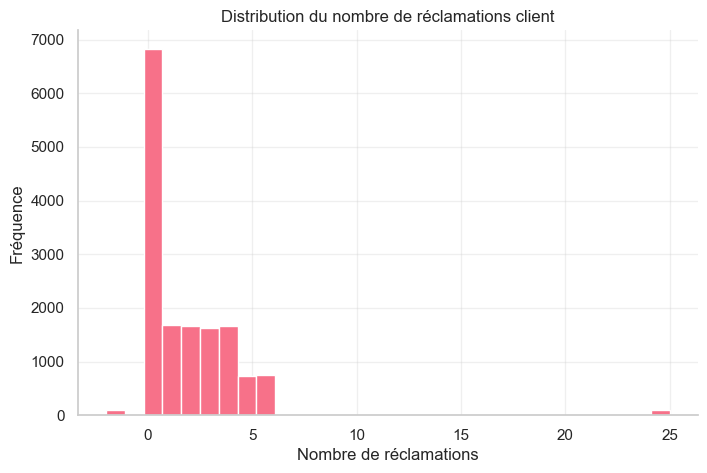

In [1186]:
print(df['nombre_reclamations_client'].value_counts())
plt.figure(figsize=(8,5))
plt.hist(df['nombre_reclamations_client'], bins=30)
plt.title("Distribution du nombre de réclamations client")
plt.xlabel("Nombre de réclamations")
plt.ylabel("Fréquence")
plt.show()

Dans la colonne `nombre_reclamations_client`, des valeurs abherente ont été détectées, notamment  `-2` et `25` 
- la valeur `-2` est incohérente , car le nombre de reclamations ne peut pas etre negatif.
- la valeur  `25` semble anormalement élevée par rapport au reste des valeurs.

Version_precedente
1.0    2556
0.9    2550
0      2533
1.1    2516
2.0    2512
1.2    2477
Name: count, dtype: int64


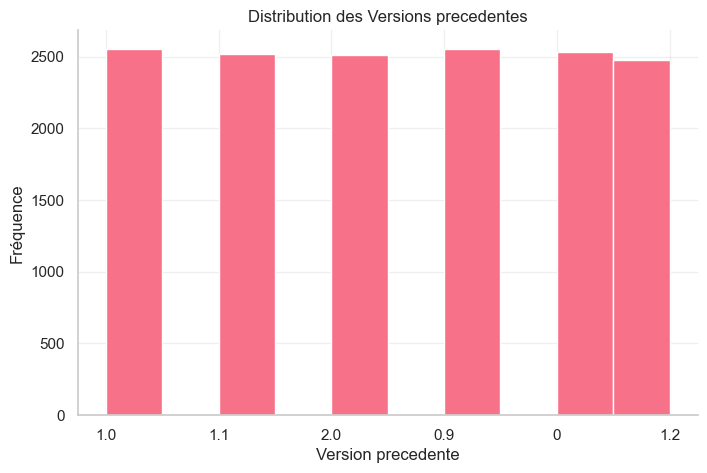

In [1187]:
print(df['Version_precedente'].value_counts())
plt.figure(figsize=(8,5))
plt.hist(df['Version_precedente'])
plt.title("Distribution des Versions precedentes")
plt.xlabel("Version precedente")
plt.ylabel("Fréquence")
plt.show()

On a 1311 clients qui n'ont pas de version précedente on va alors transformer aucune en 0

date_installation
2019    2035
2023    1967
2021    1961
2020    1951
2022    1948
2018    1918
2024    1858
2025    1506
Name: count, dtype: int64


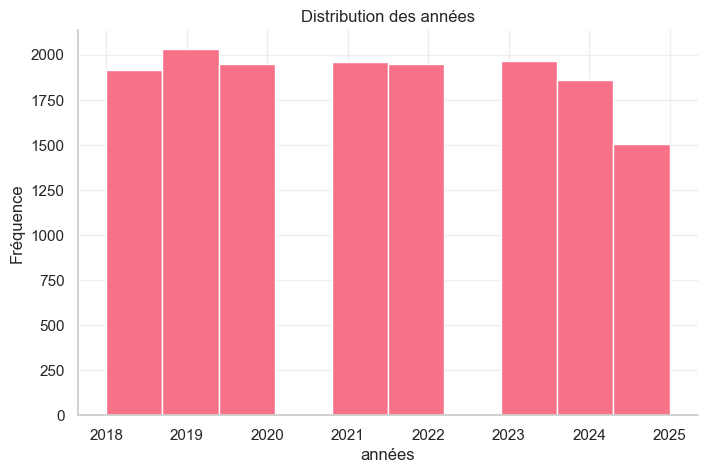

In [1188]:
years = df['date_installation'].dt.year
print(years.value_counts())
plt.figure(figsize=(8,5))
plt.hist(years)
plt.title("Distribution des années")
plt.xlabel("années")
plt.ylabel("Fréquence")
plt.show()

Remplacer les valeurs `aucune` dans la variable `Version_precedente`

### 3.4 Analyse statistique des variables qualitatives

In [1189]:
df.describe()

,date_installation,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
count,15144,15144.000000,15144.000000,15144.000000,15144.000000,15144.000000
mean,2021-11-14 09:27:17.400951040,3.480586,1.785988,97.737454,47.301125,13.104068
min,2018-01-01 00:00:00,1.000000,-2.000000,30.000000,0.010000,1.000000
25%,2019-11-30 00:00:00,2.000000,0.000000,48.000000,19.185000,6.000000
50%,2021-11-09 00:00:00,5.000000,1.000000,105.000000,47.165000,11.000000
75%,2023-10-16 00:00:00,5.000000,3.000000,140.000000,73.662500,20.000000
max,2025-12-31 00:00:00,5.000000,25.000000,202.000000,100.000000,30.000000
std,NaN,1.691179,2.708217,48.441381,30.146825,8.310133


d'après le tableau ci dessus on a les statistique suivantes:
- l'existence d'une date future dans la colonne `date_installation` ce qui est absurde 
- moyenne du `nombre_essais_installation` est de 2.98, qui est moyen par rapport au nombre d'essais qui varie entre 1 et 5
- moyenne du `nombre_reclamations_client` est de 2.83, le moyenne est proche de la mediane ce qui indique une ue distribution symetrique  on constate que `le coefficient de variation` est egale a 0.865 ce qui insique une dispersion forte des données donc possibilité d'avoir des valeurs aberrantes
- `Duree_installation_minutes` et `Debit_reseau_Mbps` il ya une possibilitées d'avoir des valeurs aberrantes dans ces deux variables du l'ecart important entre l'ecart-type et la distribution des données entre les quartiles.
- l’écart type (46.1)  de la variables `Duree_installation_minutes` indique que certaines installations sont beaucoup plus rapides ou lentes que la moyenne.

### 3.5 Analyse statistique des variables quantitatives

In [1190]:
df.describe(include='object')

,Nom_produit,version_produit,Gouvernorat,Id_Client,Type_client,Systeme_exploitation_poste,installation_reussie,client_a_reclame,client_satisfait,Remarques,Technicien_ID,Mode_installation,Tentative_installation_weekend,Version_precedente
count,15144,15144.0,15144,14970,15144,15144,15046,15144,15144,8172,15144,15144,15144,15144
unique,4,7.0,24,12715,4,13,2,2,2,7,50,2,2,6
top,MAKATIB,1.0,Ariana,CMA10328,EPNA,Win10,non,oui,non,version incompatible,TECH_045,Technicien_sur_site,non,1.0
freq,3827,2298.0,691,4,3862,2341,8328,8905,8924,2891,337,7584,7708,2556


### 3.6 Covariance

In [1191]:
df_num = df.select_dtypes(include=[np.number])
cov = df_num.cov()
cov

,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
nombre_essais_installation,2.860087,2.466987,73.528681,-19.094668,-3.310797
nombre_reclamations_client,2.466987,7.334437,64.689037,-17.418976,-2.884747
Duree_installation_minutes,73.528681,64.689037,2346.567399,-933.831813,-18.880290
Debit_reseau_Mbps,-19.094668,-17.418976,-933.831813,908.831079,17.853281
Taille_site_postes,-3.310797,-2.884747,-18.880290,17.853281,69.058310


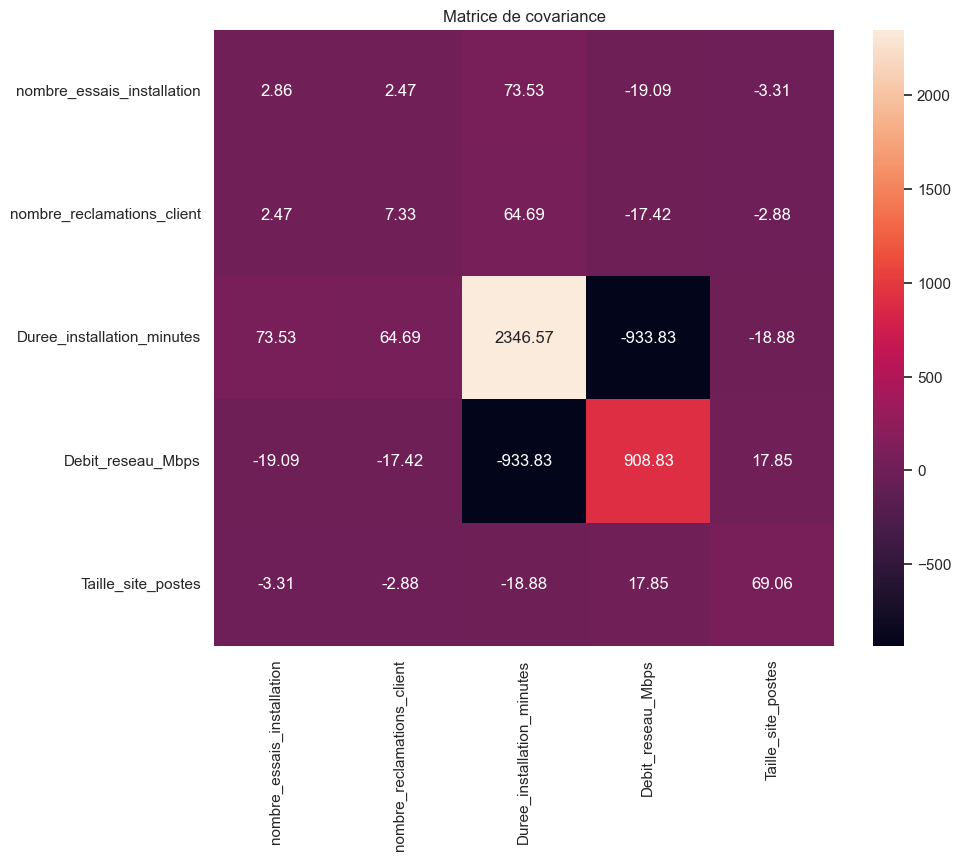

In [1192]:
plt.figure(figsize=(10,8))
sns.heatmap(cov, annot=True, fmt=".2f")
plt.title("Matrice de covariance")
plt.show()

In [1193]:
df.columns

Index(['Nom_produit', 'version_produit', 'date_installation', 'Gouvernorat',
       'Id_Client', 'Type_client', 'Systeme_exploitation_poste',
       'installation_reussie', 'nombre_essais_installation',
       'client_a_reclame', 'nombre_reclamations_client', 'client_satisfait',
       'Remarques', 'Technicien_ID', 'Duree_installation_minutes',
       'Debit_reseau_Mbps', 'Taille_site_postes', 'Mode_installation',
       'Tentative_installation_weekend', 'Version_precedente'],
      dtype='object')

### 3.7 Coefficient de corrélation

In [1194]:
coeff_corr = df_num.corr(method='pearson')
coeff_corr

,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
nombre_essais_installation,1.000000,0.538634,0.897533,-0.374525,-0.235578
nombre_reclamations_client,0.538634,1.000000,0.493095,-0.213352,-0.128179
Duree_installation_minutes,0.897533,0.493095,1.000000,-0.639456,-0.046901
Debit_reseau_Mbps,-0.374525,-0.213352,-0.639456,1.000000,0.071264
Taille_site_postes,-0.235578,-0.128179,-0.046901,0.071264,1.000000


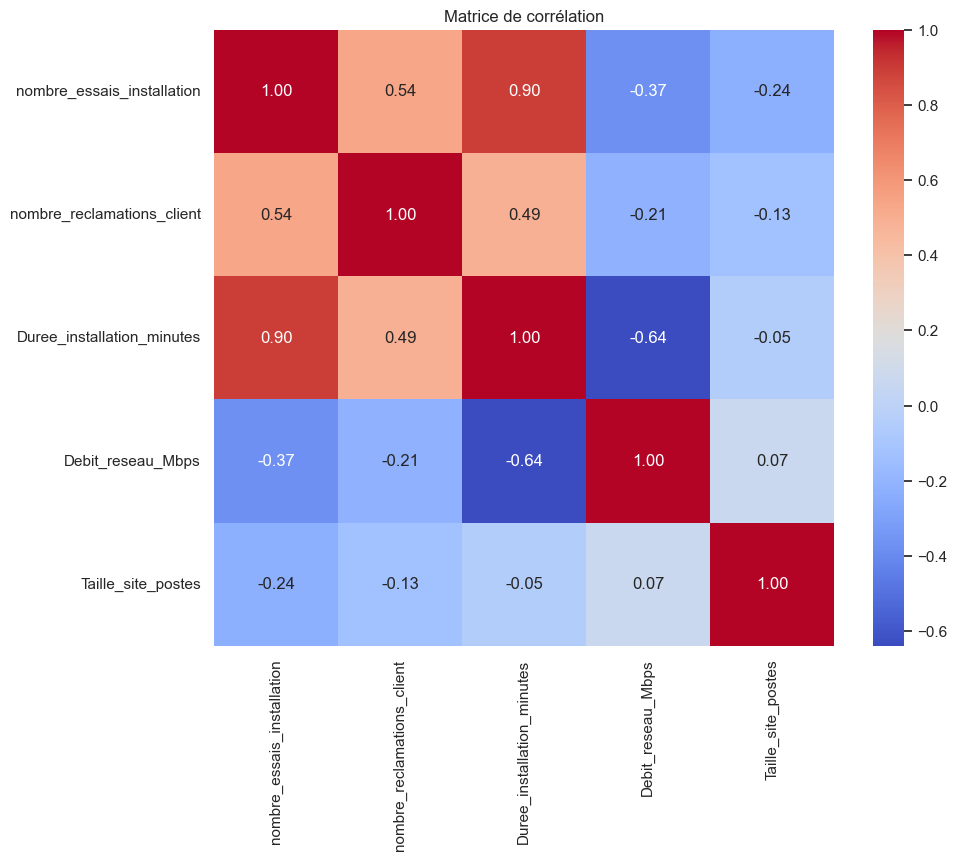

In [1195]:
plt.figure(figsize=(10,8))
sns.heatmap(coeff_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

### 3.6 Detection des Valeurs Aberrantes :

> *méthode 1* : visualisation

<Axes: xlabel='nombre_reclamations_client'>

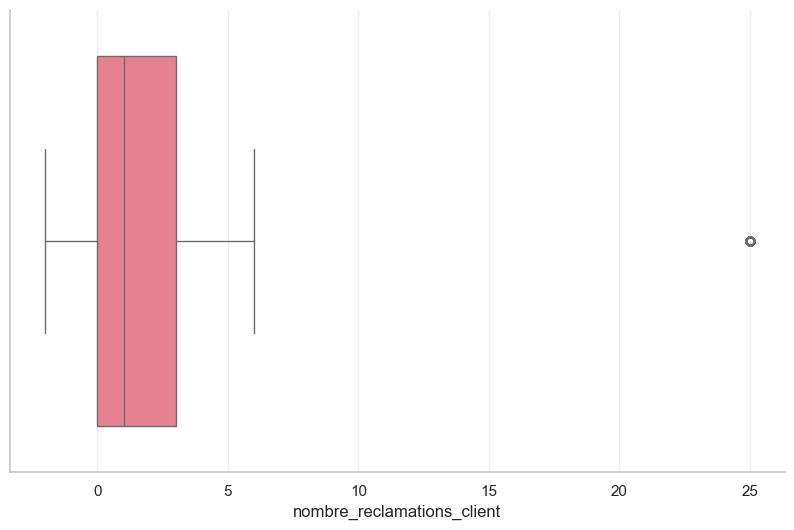

In [1196]:
sns.boxplot(x=df['nombre_reclamations_client']) 

> *méthode 2* : IQR

In [1197]:
Q1 = df['nombre_reclamations_client'].quantile(0.25)
Q3 = df['nombre_reclamations_client'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df['nombre_reclamations_client'] > lower) & (df['nombre_reclamations_client'] < upper)]

print(Q1, Q3, IQR)


0.0 3.0 3.0


la methode d'interquartile ne détecte pas les valeurs négatives proches comme -2 car la marge de confiance est [-3.5,8.5] qui est une valeur abherente comme `nombre_reclamations_client` ne peut pas etre négatif , donc il  faut supprimer cette valeur et la valeur 25 detecter par IQR.

<Axes: xlabel='Debit_reseau_Mbps'>

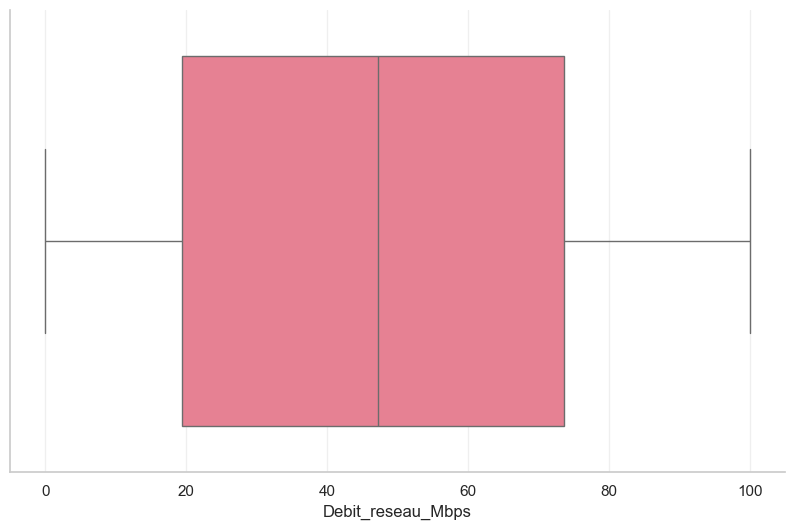

In [1198]:
sns.boxplot(x=df['Debit_reseau_Mbps']) 

In [1199]:
Q1 = df['Debit_reseau_Mbps'].quantile(0.25)
Q3 = df['Debit_reseau_Mbps'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['Debit_reseau_Mbps'] < Q1 - 1.5 * IQR) | (df['Debit_reseau_Mbps'] > Q3 + 1.5 * IQR)]
print(outliers["Debit_reseau_Mbps"].value_counts())
print(Q1, Q3, IQR)

Series([], Name: count, dtype: int64)
19.36 73.66 54.3


<Axes: xlabel='Duree_installation_minutes'>

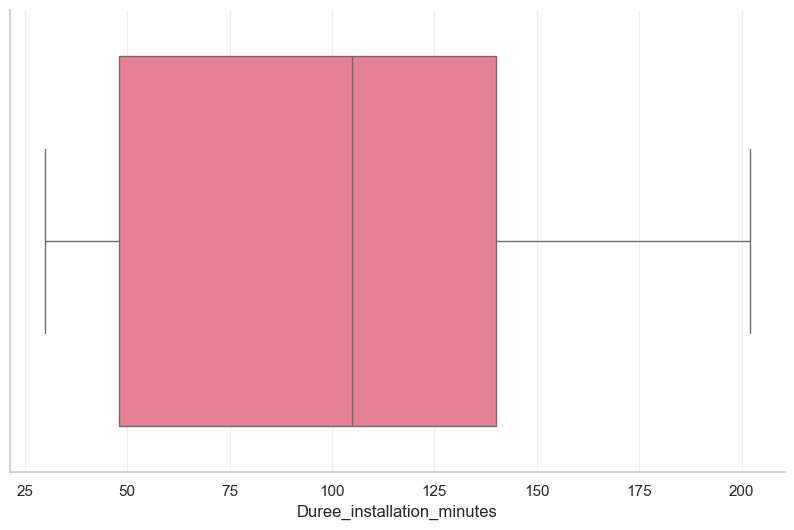

In [1200]:
sns.boxplot(x=df['Duree_installation_minutes']) 

Il n y a pas de valeurs aberrantes dans les colonnes `Debit_reseau_Mbps` et `Duree_installation_minutes`

<Axes: xlabel='date_installation'>

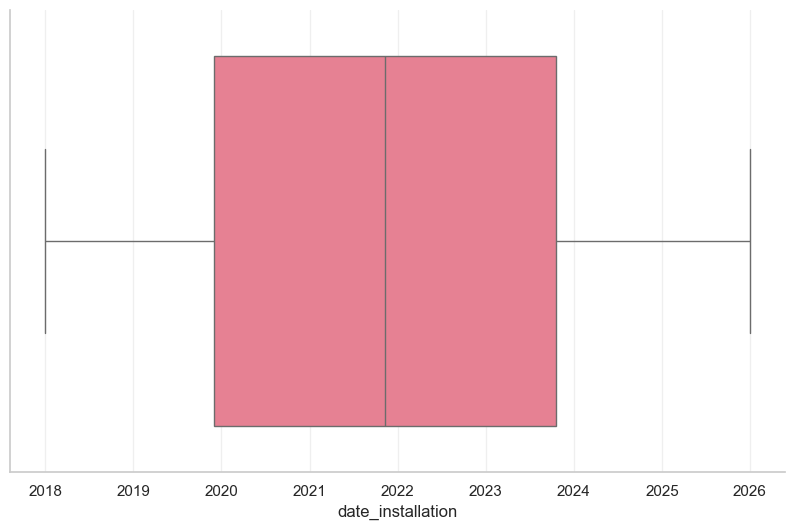

In [1201]:
sns.boxplot(x=df['date_installation']) 

In [1202]:
Q1 = df['date_installation'].quantile(0.25)
Q3 = df['date_installation'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['date_installation'] > Q1 - 1.5 * IQR) & (df['date_installation'] < Q3 + 1.5 * IQR)]
print(df["date_installation"].value_counts())
print(Q1, Q3, IQR)

date_installation
2024-06-06    14
2022-07-16    14
2020-11-09    14
2019-12-26    13
2023-02-07    13
              ..
2018-04-27     1
2024-12-05     1
2018-04-06     1
2025-01-09     1
2018-09-28     1
Name: count, Length: 2895, dtype: int64
2019-12-02 00:00:00 2023-10-19 00:00:00 1417 days 00:00:00


la méthode IQR à détecter une valeur aberrente la data 2032 qu'il faut la supprimer 

> *Méthode 3* : Z-score

* distribution normale ou non :

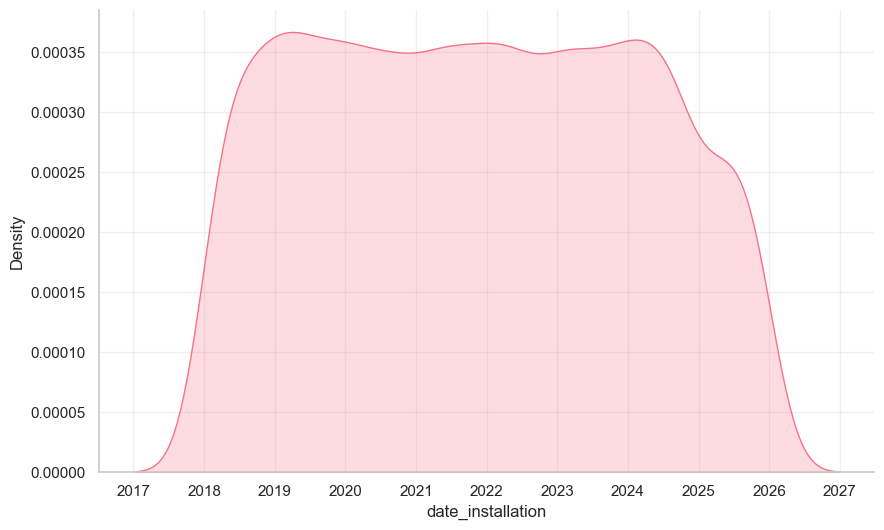

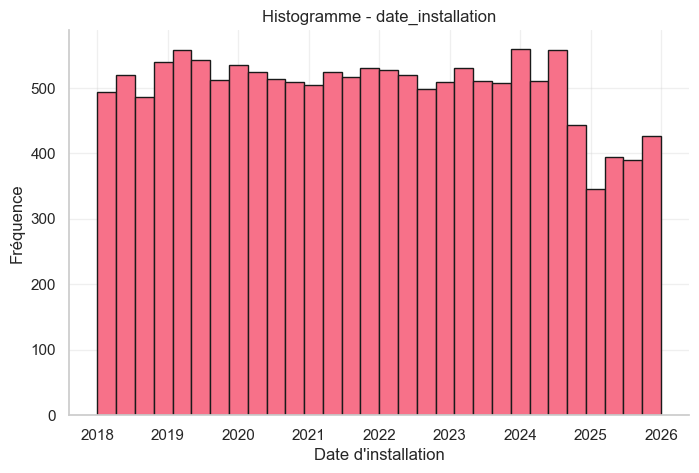

In [1203]:
import scipy.stats as stats
from scipy.stats import kstest
import matplotlib.pyplot as plt

sns.kdeplot(df['date_installation'], fill=True)

plt.figure(figsize=(8,5))
plt.hist(df["date_installation"], bins=30, edgecolor='k')
plt.title("Histogramme - date_installation")
plt.xlabel("Date d'installation")
plt.ylabel("Fréquence")
plt.show()

## 4. Préparation des données

### 4.1 Nettoyage des données

* Nettoyage des valeurs abérrantes :

In [1204]:
df = df[df["nombre_reclamations_client"]!=-2]

* Correction de l'incohérence des données dans `Systeme_exploitation_poste` :

In [1205]:
df['Systeme_exploitation_poste'] = df['Systeme_exploitation_poste'].replace(
    ['win10', 'Win 10', 'Win10'],'Win10')

* Nettoyage des valeurs nulles:

si le porcentage de valeur manquante est inferieur à 5% alors on supprime les lignes avec des valeurs manquantes sinon on impute

In [1206]:
#df = df.dropna(subset=["Id_Client"])
threshold = len(df) * 0.05
cols_to_drop = df.columns[(df.isna().sum() <= threshold) & (df.isna().sum() > 0)]
print(cols_to_drop)
df.dropna(subset=cols_to_drop, inplace=True )

Index(['Id_Client', 'installation_reussie'], dtype='object')


In [1207]:
df["Remarques"].isna().sum() / len(df) * 100

np.float64(46.31280388978931)

on a 12% > a 5% d'ou on peut pas supprimer il faut bien remplacer les valeurs manquantes

### 4.2 Imputation des valeurs manquantes basée sur l’analyse statistique

### 4.2.1 Analyse des relations entre variables

* Dependance entre la variable `Remarques` et les variables qualitatives :

In [1208]:
cat_cols = [
    'Nom_produit', 'Gouvernorat', 'Type_client',
    'Systeme_exploitation_poste', 'client_a_reclame',
    'client_satisfait', 'Technicien_ID',
    'Mode_installation', 'Tentative_installation_weekend',
    'version_produit','Version_precedente', 'installation_reussie'
]

In [1209]:
from scipy.stats import chi2_contingency

results_chi2 = []

for col in cat_cols:
    ct = pd.crosstab(df[col], df["Remarques"])
    
    chi2, p, dof, Et = chi2_contingency(ct)
    
    # condition
    valid = (Et >= 5).all()
    
    results_chi2.append({
        "variable": col,
        "p_value": p,
        "dependence": p < 0.05,
        "condition_ok": valid
    })

pd.DataFrame(results_chi2).sort_values("p_value")

,variable,p_value,dependence,condition_ok
9,version_produit,0.000000e+00,True,True
2,Type_client,1.193605e-45,True,True
3,Systeme_exploitation_poste,8.065972e-36,True,False
1,Gouvernorat,9.331791e-15,True,True
7,Mode_installation,8.794657e-12,True,True
0,Nom_produit,1.841465e-10,True,True
11,installation_reussie,1.152631e-01,False,True
5,client_satisfait,2.965821e-01,False,False
6,Technicien_ID,3.259715e-01,False,True
4,client_a_reclame,3.580090e-01,False,False


- dependance avec `version_produit`, `Type_client`, `Gouvernorat`, `Mode_installation` et `Nom_produit` 
- test khi deux ne marche pas sur Systeme_exploitation_poste il faut faire un autre test
- explication mathématiques du khi deux 

cas de `Nom_produit`:

In [1210]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Nom_produit'], df['Remarques'])
chi2, p, _, _ = chi2_contingency(table)
print(p)

1.8414649809093105e-10


- 0.02 < 0.05 donc il y a dependence entre les deux variables 
- on constate qu'il ya une dependence siginificative entre les deux variables `Nom_produit` et `Remarques` d'ou l'idee dimputer selon le nom de porduit est possible

    Cas 1 : manque espace disque

In [1211]:
pd.crosstab(df['Nom_produit'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Nom_produit,,,,,,,
GRB,0.136086,0.107543,0.098879,0.089195,0.095311,0.097859,0.375127
INSAF,0.132085,0.111842,0.109312,0.109312,0.098178,0.085526,0.353745
MADANIA,0.148148,0.103103,0.109610,0.096096,0.106607,0.097097,0.339339
MAKATIB,0.124628,0.088878,0.096822,0.164846,0.096822,0.083416,0.344588


- Pour la remarque manque espace disque est particulièrement élevé pour MAKATIB (0.149)
- Pour les autres remarques ils ont des valeurs proches entre produits donc on ne peut rien dire

In [1212]:
pd.crosstab(df['Taille_site_postes'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Taille_site_postes,,,,,,,
1,0.112994,0.135593,0.101695,0.101695,0.084746,0.129944,0.333333
2,0.121053,0.084211,0.084211,0.100000,0.105263,0.100000,0.405263
3,0.136612,0.120219,0.125683,0.092896,0.076503,0.114754,0.333333
4,0.154705,0.089314,0.102073,0.089314,0.094099,0.090909,0.379585
5,0.158155,0.093904,0.110379,0.085667,0.100494,0.085667,0.365733
6,0.125402,0.101286,0.122186,0.090032,0.107717,0.104502,0.348875
7,0.164319,0.101721,0.107981,0.095462,0.095462,0.086072,0.348983
8,0.177966,0.113559,0.091525,0.079661,0.103390,0.091525,0.342373
9,0.122241,0.120543,0.096774,0.098472,0.091681,0.083192,0.387097


- Quand `Taille_site_postes` supérieur ou égal à 26 le taux de `Remarques` manque espace disque augmente

> Regle 1 : imputer `Remarque` par manque espace disque quand le `Nom_produit` est MAKATIB et `Taille_site_postes` supérieur ou égal à 26 

    Cas 2 : version incompatible

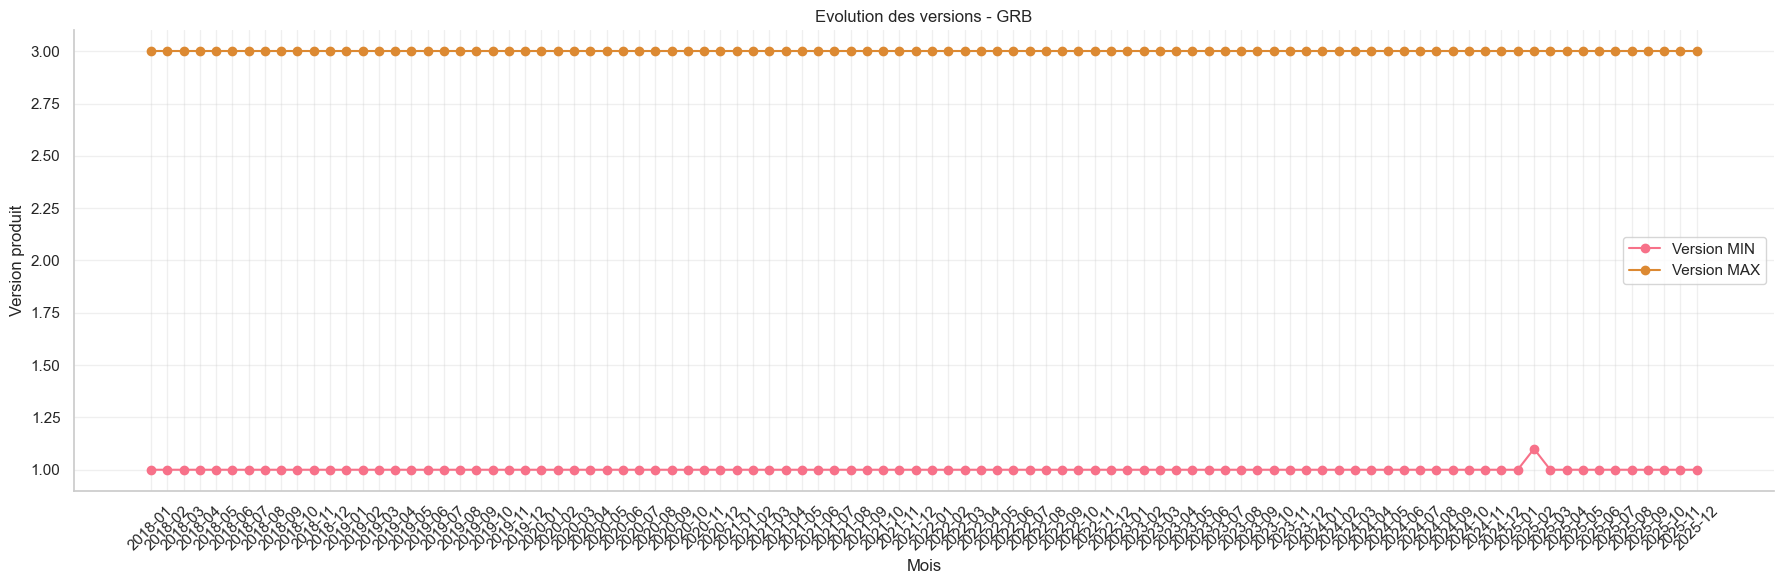

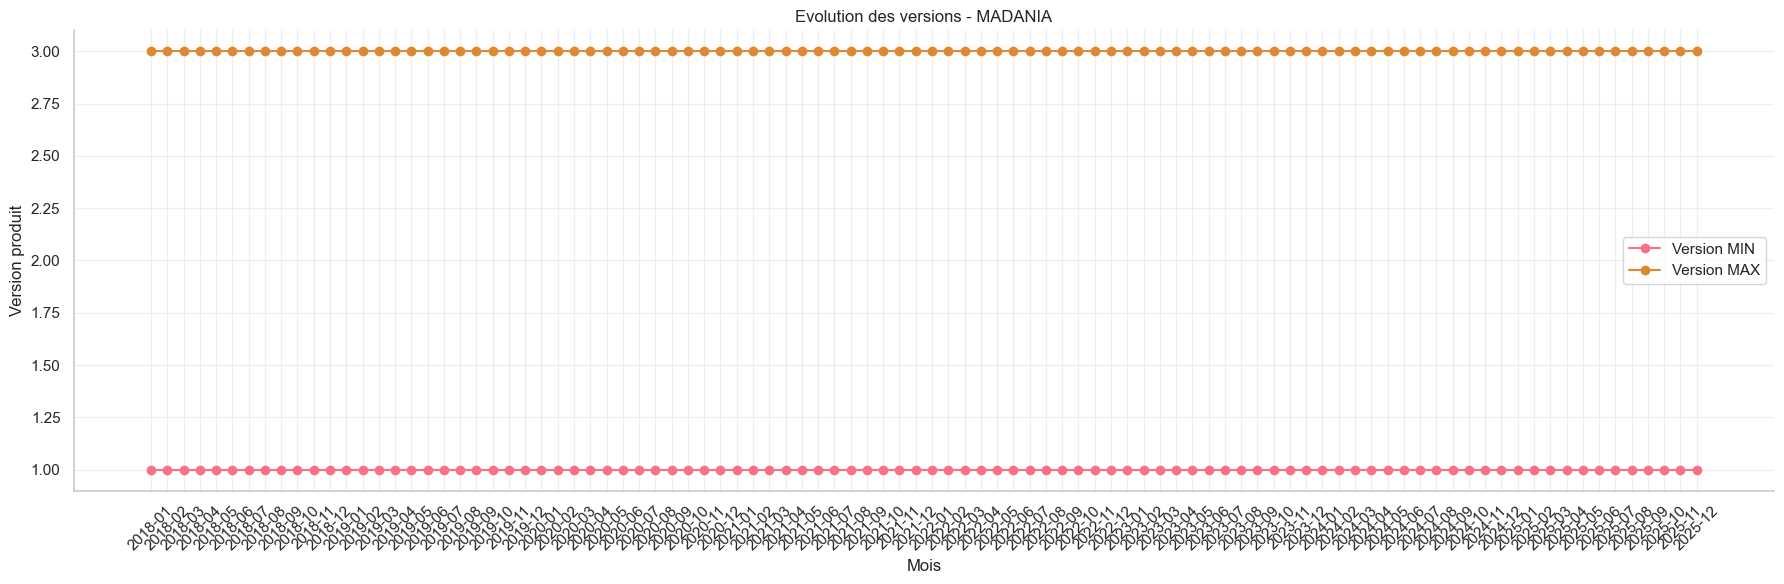

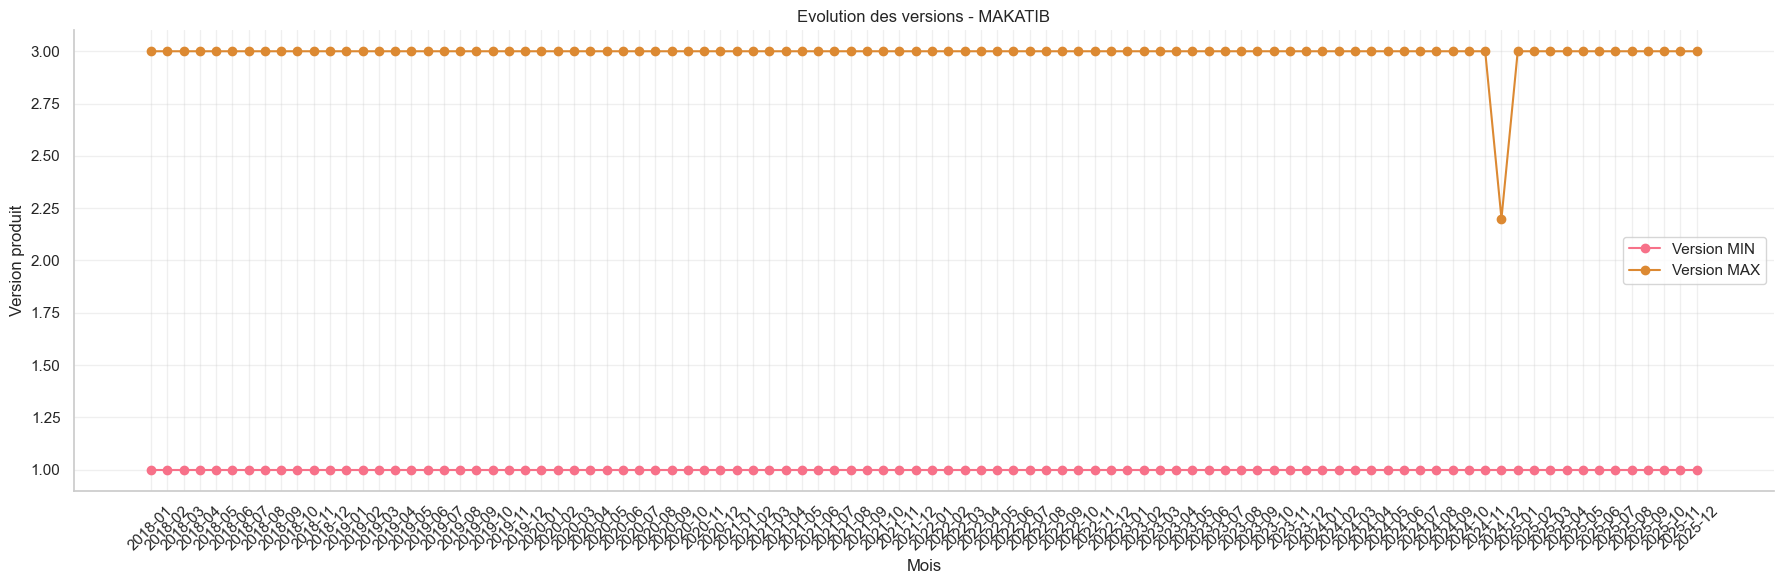

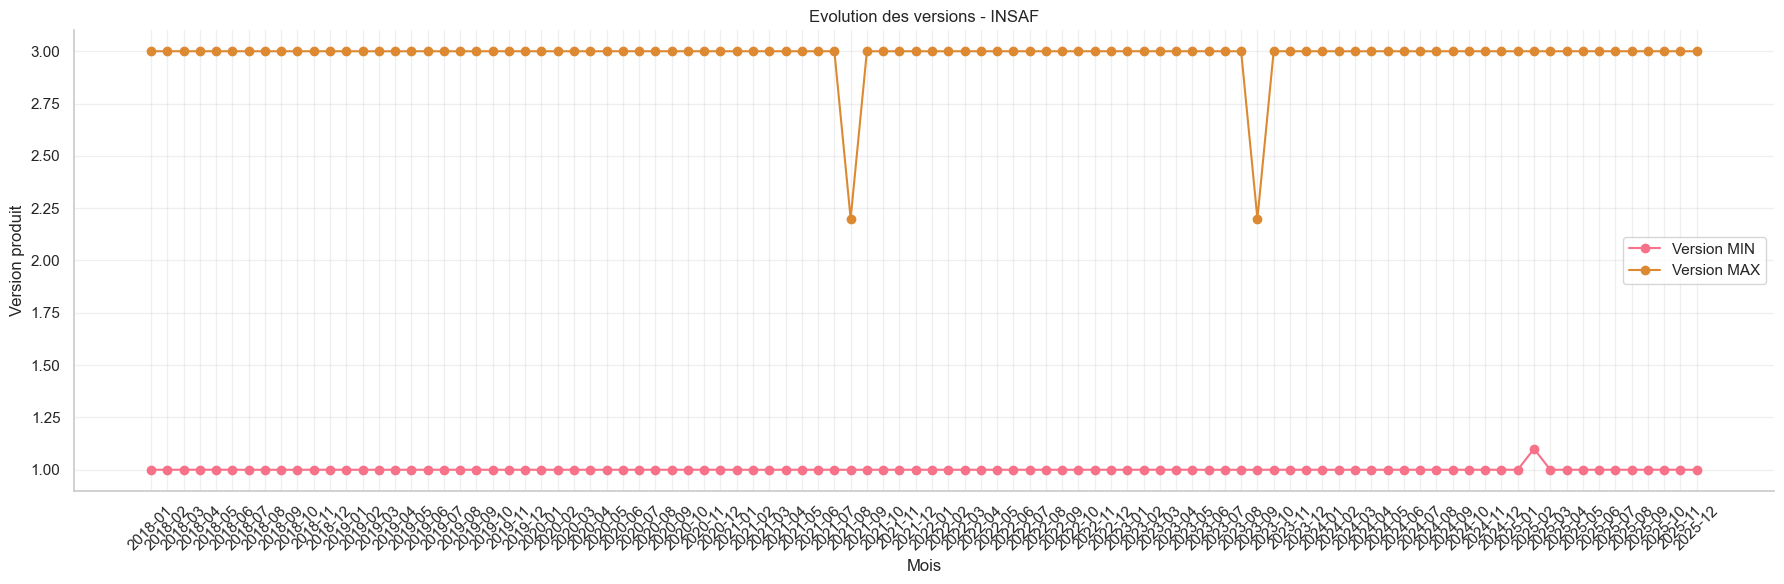

In [1213]:
df = df.copy()

df['version_produit'] = pd.to_numeric(df['version_produit'], errors='coerce')
df['date_installation'] = pd.to_datetime(df['date_installation'])

df['mois'] = df['date_installation'].dt.to_period('M')

produits = ['GRB', 'MADANIA', 'MAKATIB', 'INSAF']

for produit in produits:
    
    subset = df[df['Nom_produit'] == produit]
    
    agg = subset.groupby('mois')['version_produit'].agg(['min', 'max']).reset_index()
    plt.figure(figsize=(18, 6))
    
    plt.plot(agg['mois'].astype(str), agg['min'], marker='o', label='Version MIN')
    plt.plot(agg['mois'].astype(str), agg['max'], marker='o', label='Version MAX')
    
    plt.title(f"Evolution des versions - {produit}")
    plt.xlabel("Mois")
    plt.ylabel("Version produit")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
df = df.drop(columns="mois")
df['version_produit'] = df['version_produit'].astype(object)

- L'écart élevé entre les versions installées reflète une mauvaise synchronisation des mises à jour, ce qui peut engendrer des anomalies fonctionnelles, notamment des problèmes de compatibilité entre versions.

> Regle 2 : imputer `Remarque` par version incompatible quand il y a l'écart entre le min et le max des `version_produit` installer durant ce mois est superieur à 1

    Cas 3 : Problème adressage ip

In [1214]:
pd.crosstab(df['Type_client'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Type_client,,,,,,,
Collectivité locale,0.111686,0.122544,0.101344,0.093071,0.099793,0.102378,0.369183
EPA,0.107994,0.101112,0.107464,0.109052,0.100582,0.086289,0.387507
EPNA,0.219002,0.089311,0.103088,0.085986,0.099762,0.086461,0.316390
Ministère,0.095945,0.099407,0.102868,0.172107,0.096934,0.089021,0.343719


- La `Remarques` Problème adressage ip est particulièrement élevé pour EPNA (0.169)
- Pour les autres remarques ils ont des valeurs proches entre `Type_client` donc on ne peut rien dire

In [1215]:
pd.crosstab(df['Mode_installation'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Mode_installation,,,,,,,
Technicien_sur_site,0.106177,0.107198,0.113323,0.114089,0.103114,0.088055,0.368045
Télémaintenance,0.163442,0.098462,0.094246,0.116071,0.095486,0.093750,0.338542


- La `Remarques` Problème adressage ip est particulièrement élevé pour Télémaintenance (0.166898)
- Pour les autres remarques ils ont des valeurs proches entre `Mode_installation` donc on ne peut rien dire

In [1216]:
pd.crosstab(df['Gouvernorat'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Gouvernorat,,,,,,,
Ariana,0.107042,0.087324,0.104225,0.098592,0.092958,0.098592,0.411268
Ben Arous,0.136490,0.111421,0.119777,0.114206,0.108635,0.114206,0.295265
Bizerte,0.110738,0.130872,0.124161,0.117450,0.093960,0.087248,0.335570
Béja,0.180233,0.069767,0.098837,0.151163,0.110465,0.066860,0.322674
Gabès,0.105882,0.120588,0.091176,0.108824,0.102941,0.079412,0.391176
Gafsa,0.225705,0.062696,0.075235,0.075235,0.097179,0.090909,0.373041
Jendouba,0.227273,0.078788,0.072727,0.090909,0.112121,0.090909,0.327273
Kairouan,0.135057,0.103448,0.129310,0.135057,0.074713,0.114943,0.307471
Kasserine,0.198738,0.104101,0.053628,0.104101,0.107256,0.066246,0.365931


- La `Remarques` Problème adressage ip est particulièrement élevé pour Gafsa, Jendouba, Kasserine, Médenine, Tataouine (entre 0.2 et 0.24)
- La `Remarques` poste obsolète est particulièrement élevé pour Gafsa, Jendouba, Kasserine, Médenine, Tataouine
- Pour les autres remarques ils ont des valeurs proches entre `Gouvernorat` donc on ne peut rien dire

> Regle 3 : imputer `Remarque` par Problème adressage ip quand `Type_client` EPNA, `Mode_installation` Télémaintenance et `Gouvernorat` appartient à {Gafsa, Jendouba, Kasserine, Médenine, Tataouine}

    Cas 4 : erreur configuration poste

In [1217]:
pd.crosstab(df['Systeme_exploitation_poste'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Systeme_exploitation_poste,,,,,,,
Unknown,0.000000,0.000000,0.812500,0.000000,0.156250,0.000000,0.031250
Win10,0.128518,0.095685,0.101313,0.122889,0.091932,0.103189,0.356473
Win11,0.144681,0.111702,0.100000,0.105319,0.110638,0.091489,0.336170
Win7,0.116255,0.101852,0.111111,0.137860,0.120370,0.073045,0.339506
Win8,0.140673,0.089704,0.091743,0.117227,0.090724,0.098879,0.371050
Windows 2008 Server,0.143447,0.106295,0.087719,0.140351,0.091847,0.084623,0.345717
Windows 2012 Server,0.132632,0.105263,0.100000,0.113684,0.087368,0.091579,0.369474
Windows server 2016,0.134615,0.105030,0.076923,0.094675,0.099112,0.096154,0.393491
Windows server 2019,0.157285,0.104305,0.104305,0.094371,0.099338,0.084437,0.355960


- Les `Remarques` erreur configuration est particulièrement élevé pour Unknown et WindowsXP
- Pour les autres remarques ils ont des valeurs proches entre `Systeme_exploitation_poste` donc on ne peut rien dire

In [1218]:
pd.crosstab(df['version_produit'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
version_produit,,,,,,,
1.0,0.098054,0.038911,0.056809,0.076265,0.046693,0.041245,0.642023
1.1,0.102857,0.066939,0.075918,0.075102,0.057143,0.052245,0.569796
1.2,0.090284,0.071367,0.064488,0.067928,0.067068,0.054170,0.584695
2.0,0.180657,0.160584,0.131387,0.133212,0.145073,0.114051,0.135036
2.1,0.164522,0.152574,0.140625,0.156250,0.121324,0.119485,0.145221
2.2,0.167297,0.128544,0.137996,0.160681,0.145558,0.123819,0.136106
3.0,0.158454,0.119807,0.135266,0.154589,0.131401,0.151691,0.148792


- Les `Remarques` erreur configuration et poste obsolète sont particulièrement élevé pour `version_produit`supérieur ou égal à 2.0
- Pour les autres remarques ils ont des valeurs proches entre `version_produit` donc on ne peut rien dire

> Regle 4 : imputer `Remarque` par erreur configuration poste quand `Systeme_exploitation_poste` est Unkown ou WindowsXP et `version_produit`supérieur ou égal à 2.0

    Cas 5 : poste obsolète

> Regle 5 : imputer `Remarque` par poste obsolète quand `version_produit`supérieur ou égal à 2.0 et `Gouvernorat` appartient à {Gafsa, Jendouba, Kasserine, Médenine, Tataouine}

* Dependanc entre la variable `Remarques` et les variables qualitatives :

In [1219]:
num_cols = [
    'nombre_essais_installation',
    'nombre_reclamations_client', 'Duree_installation_minutes',
    'Debit_reseau_Mbps', 'Taille_site_postes'
]

In [1220]:
X = df[num_cols].astype(float)
le = LabelEncoder()
y = le.fit_transform(df["Remarques"].astype(str))
mi = mutual_info_classif(X, y, random_state=0)
mi_results = pd.DataFrame({
    "Variable": num_cols,
    "Mutual Information": mi
}).sort_values(by="Mutual Information", ascending=False)

print(mi_results)

                     Variable  Mutual Information
2  Duree_installation_minutes            0.472539
0  nombre_essais_installation            0.465542
1  nombre_reclamations_client            0.405342
3           Debit_reseau_Mbps            0.282542
4          Taille_site_postes            0.054032


- L’information mutuelle obtenue (0.226) indique que le débit réseau contient une information statistiquement significative sur les remarques, mais cette dépendance est partielle et probablement concentrée sur certaines remarques car la répartiton est déséquilibrée
- Pour les autres variable l'information mutuelle obtenue est proche de 0 ce qui signifie qu'il n y a pas de dépendance avec `Remarques`

In [1221]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# X
X = df[["Debit_reseau_Mbps"]].astype(float)

# y
le = LabelEncoder()
y = le.fit_transform(df["Remarques"].astype(str))

# MI
mi = mutual_info_classif(X, y)

print(mi)

[0.28458374]


    Cas 6 : connexion serveur lente et problème réseau

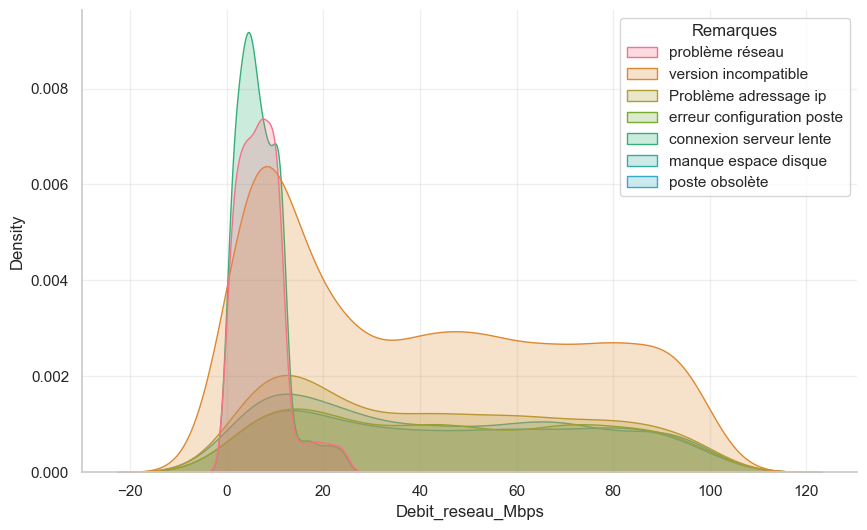

In [1222]:
sns.kdeplot(data=df, x="Debit_reseau_Mbps", hue="Remarques", fill=True)
plt.show()

<Axes: xlabel='Remarques', ylabel='Debit_reseau_Mbps'>

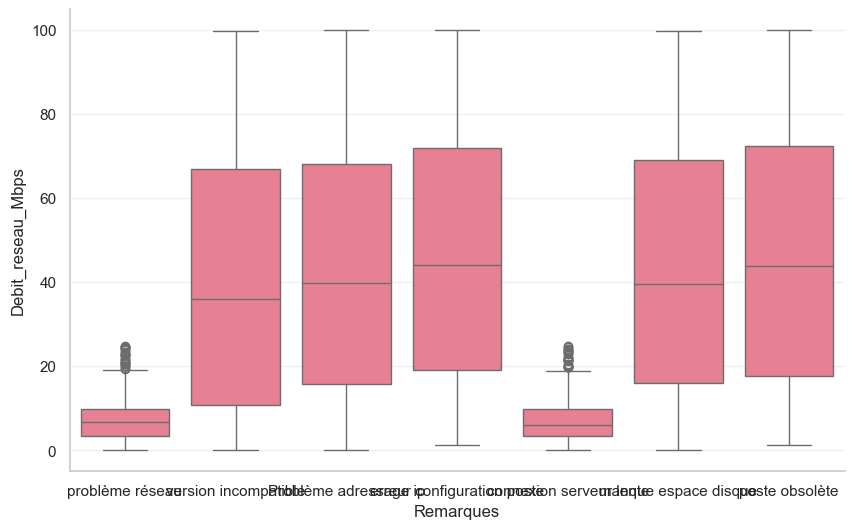

In [1223]:
import seaborn as sns

sns.boxplot(x="Remarques", y="Debit_reseau_Mbps", data=df)

On remarque que le débit réseau influence surtout les problèmes liés directement à la connectivité comme `connexion serveur lente` et `problème réseau`. Les autres types de remarques ne semblent pas dépendre du débit.

on constate qu'il ya une dependence siginificative entre les deux variables `Debit_reseau_Mbps` et `Remarques` d'ou l'idee dimputer selon le `Debit_reseau_Mbps` est possible

In [1224]:
df.groupby("Remarques")["Debit_reseau_Mbps"].mean()

Remarques
Problème adressage ip         42.875237
connexion serveur lente        6.819229
erreur configuration poste    46.143204
manque espace disque          43.387224
poste obsolète                45.930330
problème réseau                7.086791
version incompatible          40.443805
Name: Debit_reseau_Mbps, dtype: float64

> Regle 6 : imputer `Remarque` par connexion serveur lente ou problème réseau quand `Debit_reseau_Mbps` est inférieur ou égal à 6

### 4.2.2 Nettoyage des valeurs manquantes dans la colonne `Remarques`

In [1225]:
import numpy as np

mask_missing = df["Remarques"].isna()

# -------------------------
# Règle 1
# -------------------------
df.loc[
    mask_missing &
    (df["Nom_produit"] == "MAKATIB") &
    (df["Taille_site_postes"] >= 26),
    "Remarques"
] = "manque espace disque"

# -------------------------
# Règle 2
# -------------------------
df.loc[
    mask_missing &
    (df.groupby(df["date_installation"].dt.to_period("M"))["version_produit"]
        .transform(lambda x: x.max() - x.min()) > 1),
    "Remarques"
] = "version incompatible"

# -------------------------
# Règle 3
# -------------------------
gouvernorats_risque = ["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"]

df.loc[
    mask_missing &
    (df["Type_client"] == "EPNA") &
    (df["Mode_installation"] == "Télémaintenance") &
    (df["Gouvernorat"].isin(gouvernorats_risque)),
    "Remarques"
] = "Problème adressage ip"

# -------------------------
# Règle 4
# -------------------------
df.loc[
    mask_missing &
    (df["Systeme_exploitation_poste"].isin(["Unknown", "WindowsXP"])) &
    (df["version_produit"] >= 2.0),
    "Remarques"
] = "erreur configuration poste"

# -------------------------
# Règle 5
# -------------------------
df.loc[
    mask_missing &
    (df["version_produit"] >= 2.0) &
    (df["Gouvernorat"].isin(gouvernorats_risque)),
    "Remarques"
] = "poste obsolète"

# -------------------------
# Règle 6
# -------------------------
mask = mask_missing & (df["Debit_reseau_Mbps"] <= 6)

df.loc[mask, "Remarques"] = np.random.choice(
    ["connexion serveur lente", "problème réseau"],
    size=mask.sum()
)

In [1226]:
df.isna().sum()

Nom_produit                       0
version_produit                   0
date_installation                 0
Gouvernorat                       0
Id_Client                         0
Type_client                       0
Systeme_exploitation_poste        0
installation_reussie              0
nombre_essais_installation        0
client_a_reclame                  0
nombre_reclamations_client        0
client_satisfait                  0
Remarques                         0
Technicien_ID                     0
Duree_installation_minutes        0
Debit_reseau_Mbps                 0
Taille_site_postes                0
Mode_installation                 0
Tentative_installation_weekend    0
Version_precedente                0
dtype: int64

* Remplacer Unknown par WindowsXP dans `Systeme_exploitation_poste` :

In [1227]:
df["Systeme_exploitation_poste"] = df["Systeme_exploitation_poste"].replace("Unknown","WindowsXP")

In [1228]:
df["Systeme_exploitation_poste"].value_counts()

Systeme_exploitation_poste
Win10                  2361
Win11                  2270
Windows server 2022    1935
Windows server 2019    1922
Windows server 2016    1903
Win8                   1083
Win7                   1074
Windows 2012 Server    1065
Windows 2008 Server    1065
WindowsXP               130
Name: count, dtype: int64

In [1229]:
df["Mode_installation"].value_counts()

Mode_installation
Technicien_sur_site    7410
Télémaintenance        7398
Name: count, dtype: int64

## 5. Feature engineering

### 5.1 Encodage des variables

In [1230]:
#encodage sur la dataframe qu'on va utiliser pour poduire des modeles fiables 
# variables catégorielles binaires:

binary_cols = [
    "installation_reussie",
    "client_satisfait",
    "client_a_reclame",
    "Tentative_installation_weekend"
]

for col in binary_cols:
    df[col+'_encoded'] = df[col].map({"oui":1, "non":0})

#encodage des variables catégorielles:
df["version_produit_o"] = df["version_produit"]
df["version_produit_encoded"] = df.groupby("version_produit")["installation_reussie_encoded"].transform("mean")

# Creation des variables explicatives :

#variables d'efficacité :
df["taux_reussite"] = df["installation_reussie_encoded"] / df["nombre_essais_installation"]

df["temps_par_essai"] = df["Duree_installation_minutes"] / df["nombre_essais_installation"] # a voir

df["efficacite_installation"] = df["installation_reussie_encoded"] / df["Duree_installation_minutes"]

#variable de complexité :
df["complexite_site"] = df["Taille_site_postes"] * df["nombre_essais_installation"]
df["complexite_installation"] = (df["nombre_essais_installation"] * df["Duree_installation_minutes"])

#variable de satisfaction :

df["score_risque"] = (
    # réseau faible
    (df["Debit_reseau_Mbps"] < 5).astype(int) +

    # installation difficile
    (df["nombre_essais_installation"] > 2).astype(int) +

    # durée trop longue
    (df["Duree_installation_minutes"] > 120).astype(int) +

    # OS instable / ancien
    (df["Systeme_exploitation_poste"].str.contains("WindowsXP", case=False, na=False)).astype(int) +

    # produits historiquement problématiques (selon ton domaine)
    (df["Nom_produit"].isin(["GRB"])).astype(int) +

    # anciennes versions = plus de bugs
    (df["version_produit"].astype(str).str.contains("1\\.|2\\.|3\\.", na=False)).astype(int) +

    # taille site complexe
    (df["Taille_site_postes"] > 15).astype(int) 
)

df["client_risque"] = (df["score_risque"] >= 3).astype(int)
"""df2["client_risque"] = df["client_risque"]"""


df["nombre_reclamations"] = (
    df["client_a_reclame_encoded"] * df["nombre_reclamations_client"])

#variable temporelle :
df["annee"] = df["date_installation"].dt.year
df["jour_semaine"] = df["date_installation"].dt.dayofweek
df["mois"] = df["date_installation"].dt.to_period("M").astype(str)
df["weekend"] = (df["jour_semaine"] >= 5).astype(int)


#variable version :
df["upgrade"] = (df["version_produit"] == df["version_produit"].max()).astype("int")


### Regroupement de certaines modalités

In [1231]:
# taille du site :

def cat_taille(x):
    if x <= 10:
        return "petit"
    elif x <= 20:
        return "moyen"
    else:
        return "grand"

df["cat_taille"] = df["Taille_site_postes"].apply(cat_taille)


# Debit reseau :
def cat_debit(x):
    if x < 5:
        return "faible"
    elif x < 20:
        return "moyen"
    else:
        return "bon"

df["cat_debit"] = df["Debit_reseau_Mbps"].apply(cat_debit)

#os 

df["os_enc"] = df.groupby("Systeme_exploitation_poste")["installation_reussie_encoded"].transform("mean")

# zone d'urbanisation :

metropolitaine = [
    "Tunis", "Ariana", "Ben Arous", "Manouba",
    "Sfax", "Sousse", "Monastir", "Nabeul", "Bizerte"
]

mixte = [
    "Mahdia", "Kairouan", "Gabès", "Zaghouan",
    "Béja", "Siliana", "Le Kef", "Tozeur", "Gafsa"
]

rurale = [
    "Jendouba", "Kasserine", "Sidi Bouzid",
    "Médenine", "Tataouine", "Kébili"
]
def classify_region(x):
    if x in metropolitaine:
        return "metropolitaine"
    elif x in mixte:
        return "mixte"
    elif x in rurale:
        return "rurale"
    else:
        return "inconnu"

df["zone_urbanisation"] = df["Gouvernorat"].apply(classify_region)


# Remarques :
df["pb_reseau"] = df["Remarques"].str.contains("réseau|connexion|serveur", case=False, na=False).astype(int)
df["pb_configuration"] = df["Remarques"].str.contains("configuration|adresse|ip", case=False, na=False).astype(int)
df["pb_materiel"] = df["Remarques"].str.contains("disque|poste|obsolète", case=False, na=False).astype(int)
df["pb_version"] = df["Remarques"].str.contains("version|incompatible", case=False, na=False).astype(int)


for col in ["Nom_produit", "Type_client", "Mode_installation","cat_taille", "cat_debit","zone_urbanisation"] : 
    df[col+"_o"] = df[col]

var_a_encoder = ["Nom_produit", "Type_client", "Mode_installation","cat_taille", "cat_debit","zone_urbanisation"]
df = pd.get_dummies(df, columns=var_a_encoder, drop_first=True)


In [1232]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

In [ ]:
"""df_kpi = df_kpi.drop(columns={"Id_Client", "Technicien_ID"})"""

'df1 = df1.drop(columns={"Id_Client", "Technicien_ID"})'

In [1234]:
df["upgrade"].value_counts()

upgrade
0    12780
1     2028
Name: count, dtype: int64

In [ ]:
df_kpi = df.copy()
var_a_effacer =["Nom_produit", 'date_installation', 'Gouvernorat',
       'Id_Client', 'Type_client', 'Systeme_exploitation_poste',
       'client_a_reclame', 'nombre_reclamations_client',
       'Remarques', 'Technicien_ID',"version_produit",
       'Debit_reseau_Mbps', 'Taille_site_postes', 'Mode_installation',
       'Version_precedente',"cat_version", "cat_taille", "cat_debit", "zone_urbanisation",
       'score_risque', 'year',"installation_reussie","client_satisfait",
    "client_a_reclame","mois","Tentative_installation_weekend",
    "Nom_produit_o", "Type_client_o", "Mode_installation_o","cat_taille_o", "cat_debit_o","zone_urbanisation_o"]

df_kpi = df_kpi.drop(columns=var_a_effacer, errors='ignore')

In [ ]:
df_kpi.columns

Index(['nombre_essais_installation', 'Duree_installation_minutes',
       'installation_reussie_encoded', 'client_satisfait_encoded',
       'client_a_reclame_encoded', 'Tentative_installation_weekend_encoded',
       'version_produit_o', 'version_produit_encoded', 'taux_reussite',
       'temps_par_essai', 'efficacite_installation', 'complexite_site',
       'complexite_installation', 'client_risque', 'nombre_reclamations',
       'annee', 'jour_semaine', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_INSAF',
       'Nom_produit_MADANIA', 'Nom_produit_MAKATIB', 'Type_client_EPA',
       'Type_client_EPNA', 'Type_client_Ministère',
       'Mode_installation_Télémaintenance', 'cat_taille_moyen',
       'cat_taille_petit', 'cat_debit_faible', 'cat_debit_moyen',
       'zone_urbanisation_mixte', 'zone_urbanisation_rurale'],
      dtype='object')

In [ ]:
import plotly.express as px

coeff_corr = df_kpi.corr(method='pearson')

fig = px.imshow(
    coeff_corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1,
    aspect="auto"
)

fig.update_layout(
    title="Matrice de corrélation interactive",
    width=1400,   
    height=1200   
)

fig.update_traces(
    hovertemplate="X: %{x}<br>Y: %{y}<br>Corr: %{z:.2f}<extra></extra>"
)

fig.show()

 ## 6.Construction des KPI

In [1238]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 6.1 KPI globaux

In [1239]:
kpi_global = {
    "nb_installations": len(df), 
    "taux_reussite": df["installation_reussie_encoded"].mean(),
    "taux_satisfaction": df["client_satisfait_encoded"].mean(),
    "taux_reclamation": df["nombre_reclamations"].mean(),
    "duree_moyenne": df["Duree_installation_minutes"].mean(),
    "nb_moyen_essais": df["nombre_essais_installation"].mean()
}
kpi_global

{'nb_installations': 14808,
 'taux_reussite': np.float64(0.45245813074014046),
 'taux_satisfaction': np.float64(0.41950297136682874),
 'taux_reclamation': np.float64(1.6404646137223122),
 'duree_moyenne': np.float64(97.0168827660724),
 'nb_moyen_essais': np.float64(3.451107509454349)}

### 5.1 PRODUIT vs OS & DURÉE

In [1240]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

In [1241]:
kpi_produit = df.groupby("Nom_produit_o").agg({
    "Duree_installation_minutes": "mean",
    "installation_reussie_encoded": "mean"
}).rename(columns={
    "Duree_installation_minutes": "temps_moyen",
    "installation_reussie_encoded": "taux_reussite"
})

print(kpi_produit.head())

               temps_moyen  taux_reussite
Nom_produit_o                            
GRB              91.219963       0.478191
INSAF            98.325314       0.447786
MADANIA          99.421956       0.443748
MAKATIB          99.167557       0.439872


In [1242]:
import plotly.express as px
pivot_os = pd.crosstab(df["Nom_produit_o"], df["Systeme_exploitation_poste"])

fig = px.imshow(
    pivot_os,
    text_auto=True,
    color_continuous_scale="RdBu",
    title="Produit vs Système d'exploitation"
)

fig.update_layout(height=500)
fig.show()

In [1243]:
fig = px.box(
    df,
    x="Nom_produit_o",
    y="Duree_installation_minutes",
    color="Nom_produit_o",
    title="Durée d'installation par produit"
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

### 5.2 VERSION vs REMARQUES

In [1244]:
kpi_version = df.groupby("version_produit")["Remarques"].count().sort_values(ascending=False)
print(kpi_version)

version_produit
1.0    2244
1.1    2200
2.0    2119
1.2    2113
2.1    2072
2.2    2032
3.0    2028
Name: Remarques, dtype: int64


In [1245]:
kpi_version = df.groupby("version_produit")["Remarques"].count().reset_index()

fig = px.bar(
    kpi_version,
    x="version_produit",
    y="Remarques",
    color="Remarques",
    title="Remarques par version produit"
)

fig.show()

### 5.3 TYPE CLIENT vs TAILLE SITE

In [1246]:
kpi_client = df.groupby("Type_client_o")["Taille_site_postes"].mean()
print(kpi_client)

Type_client_o
Collectivité locale    10.362315
EPA                    11.573887
EPNA                   11.406051
Ministère              19.310862
Name: Taille_site_postes, dtype: float64


In [1247]:
fig = px.box(
    df,
    x="Type_client_o",
    y="Taille_site_postes",
    color="Type_client_o",
    title="Taille des sites par type client"
)

fig.show()

### 5.4 SUCCÈS INSTALLATION

In [1248]:
kpi_success = {
    "taux_reussite": df["installation_reussie_encoded"].mean(),
    "moyenne_essais": df["nombre_essais_installation"].mean(),
    "temps_moyen": df["Duree_installation_minutes"].mean(),
    "taux_satisfaction": df["client_satisfait_encoded"].mean()
}
kpi_success

{'taux_reussite': np.float64(0.45245813074014046),
 'moyenne_essais': np.float64(3.451107509454349),
 'temps_moyen': np.float64(97.0168827660724),
 'taux_satisfaction': np.float64(0.41950297136682874)}

In [1249]:
import plotly.io as pio

df_grouped = df.groupby("installation_reussie")["nombre_essais_installation"].mean().reset_index()

fig = px.bar(
    df_grouped,
    x="installation_reussie",
    y="nombre_essais_installation",
    color="installation_reussie",
    color_discrete_map={0: "#e74c3c", 1: "#2ecc71"}
)

fig.show()

In [1250]:
df_grouped2 = df.groupby("installation_reussie")["Duree_installation_minutes"].mean().reset_index()

fig = px.bar(
    df_grouped2,
    x="installation_reussie",
    y="Duree_installation_minutes",
    color="installation_reussie",
    title="Durée vs Réussite"
)
fig.show()

In [1251]:
df_grouped3 = df.groupby("installation_reussie")["client_satisfait_encoded"].mean().reset_index()

fig = px.bar(
    df_grouped3,
    x="installation_reussie",
    y="client_satisfait_encoded",
    color="installation_reussie",
    title="Réussite vs Satisfaction",
    barmode="group"
)
fig.show()

### 5.5 NOMBRE ESSAIS (EFFORT TECHNIQUE)

In [1252]:
kpi_essais = df["nombre_essais_installation"].describe()
kpi_essais

count    14808.000000
mean         3.451108
std          1.696189
min          1.000000
25%          2.000000
50%          4.000000
75%          5.000000
max          5.000000
Name: nombre_essais_installation, dtype: float64

In [1253]:
df_grouped4 = df.groupby("nombre_essais_installation")["Duree_installation_minutes"].mean().reset_index()
fig = px.bar(
    df_grouped4,
    x="nombre_essais_installation",
    y="Duree_installation_minutes",
    title="Essais vs Durée (avec satisfaction)"
)

fig.show()

In [1254]:
df_grouped5 = df.groupby("client_satisfait")["nombre_essais_installation"].mean().reset_index()
fig = px.bar(
    df_grouped5,
    y="client_satisfait",
    x="nombre_essais_installation",
    title="Essais vs Satisfaction"
)
fig.show()

### 5.6 RÉCLAMATIONS CLIENT

In [1255]:
kpi_reclamation = {
    "taux_reclamation": df["client_a_reclame_encoded"].mean(),
    "moyenne_reclamations": df["nombre_reclamations"].mean()
}

kpi_reclamation

{'taux_reclamation': np.float64(0.5793490005402485),
 'moyenne_reclamations': np.float64(1.6404646137223122)}

In [1256]:
# Réclamation vs satisfaction
df_grouped6 = df.groupby("client_a_reclame")["client_satisfait_encoded"].mean().reset_index()
fig = px.bar(
    df_grouped6,
    x="client_a_reclame",
    y="client_satisfait_encoded",
    color="client_a_reclame",
    title="Impact des réclamations sur la satisfaction"
)

fig.show()

### 5.7 NOMBRE RÉCLAMATIONS

In [1257]:
kpi_nb_reclam = df["nombre_reclamations_client"].describe()
print(kpi_nb_reclam)

count    14808.000000
mean         1.642153
std          1.899920
min          0.000000
25%          0.000000
50%          1.000000
75%          3.000000
max          6.000000
Name: nombre_reclamations_client, dtype: float64


In [1258]:
fig = px.box(
    df,
    x="client_a_reclame",
    y="Duree_installation_minutes",
    color="client_a_reclame",
    title="Réclamation vs Durée"
)

fig.show()

### 5.8 SATISFACTION CLIENT

In [1259]:
taux_satisfaction = df["client_satisfait_encoded"].mean()
print("Taux satisfaction:", taux_satisfaction)

Taux satisfaction: 0.41950297136682874


In [1260]:
fig = px.box(
    df,
    x="client_satisfait",
    y="Duree_installation_minutes",
    color="client_satisfait",
    title="Satisfaction vs Durée"
)

fig.show()

### 5.81 KPI temporels

In [1261]:
kpi_temporel = df.groupby('mois').agg({
    "installation_reussie_encoded": "mean",
    "client_satisfait_encoded": "mean",
    "nombre_reclamations": "mean",
    "nombre_essais_installation": "mean",
    "Duree_installation_minutes": "mean",
    "client_a_reclame_encoded": "mean"
}).reset_index()

kpi_temporel.head()

,mois,installation_reussie_encoded,client_satisfait_encoded,nombre_reclamations,nombre_essais_installation,Duree_installation_minutes,client_a_reclame_encoded
0,2018-01,0.440000,0.420000,1.660000,3.453333,98.413333,0.580000
1,2018-02,0.480263,0.447368,1.322368,3.375000,95.269737,0.552632
2,2018-03,0.463576,0.443709,1.682119,3.503311,96.867550,0.562914
3,2018-04,0.503401,0.442177,1.326531,3.380952,91.469388,0.551020
4,2018-05,0.426829,0.396341,1.786585,3.554878,99.664634,0.603659


In [1262]:
import plotly.express as px

fig = px.line(
    kpi_temporel,
    x="mois",
    y="installation_reussie_encoded",
    markers=True,
    title="Évolution du taux de réussite"
)

fig.show()

In [1263]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

In [1264]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y=["client_satisfait_encoded", "client_a_reclame_encoded"],
    markers=True,
    title="Satisfaction vs Réclamations dans le temps"
)

fig.show()

In [1265]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="Duree_installation_minutes",
    markers=True,
    title="Évolution du temps d'installation"
)

fig.show()

In [1266]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="nombre_essais_installation",
    markers=True,
    title="Évolution du nombre d'essais"
)

fig.show()

In [1267]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="nombre_reclamations",
    markers=True,
    title="Évolution des réclamations"
)

fig.show()

In [1268]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y=["installation_reussie_encoded", "client_satisfait_encoded"],
    title="Drift qualité (réussite vs satisfaction)"
)

fig.show()

In [1269]:
installations_temps = df.groupby("mois").size().reset_index(name="nombre_installations")
fig = px.line(
    installations_temps,
    x="mois",
    y="nombre_installations",
    markers=True,
    title="Nombre d'installations dans le temps"
)

fig.show()

- installation_reussie : Nom_produit(relation faible),version_produit(relation moyenne), Gouvernorat(relation tres faible) en relation avec Debit_reseau_Mbps(relation forte) et Remarques(relation forte) et Taille_site_postes(relation negative moyenne), Systeme_exploitation_poste(relation tres forte),Technicien_ID(relation positive moyenne), nombre_essais_installatio(relation négative tres forte), client_a_reclame(relation negative forte), nombre_reclamations_client(relation negative forte), client_satisfait(relation positive tres forte), Mode_installation(relation positive moyenne), Duree_installation_minutes(relation negative forte)

- client_satisfait : Nom_produit(relation faible), version_produit(relation faible),Remarques(relation negative forte), Debit_reseau_Mbps(relation positive moyenne), Mode_installation(relation faible), nombre_essais_installation(relation negative forte), Duree_installation_minutes(relation negative forte), installation_reussie(relation positive tres forte), client_a_reclame(relation negative tres forte), nombre_reclamations_client(relation negative tres forte)

- client_a_reclame : Nom_produit(relation faible), version_produit(relation moyenne), Systeme_exploitation_poste(relation positive moyenne/forte), Remarques(relation positive tres forte), Debit_reseau_Mbps(relation positive moyenne), nombre_essais_installation(relation positive tres forte), Duree_installation_minutes(relation positive forte), installation_reussie(relation negative tres forte),  nombre_reclamations_client(relation positive tres forte), client_satisfait(relation negative tres forte)

- Duree_installation_minutes : Nom_produit(relation forte pour makatib app 20gb), version_produit(relation positive faible/moyenne), Gouvernorat(relaion forte), Systeme_exploitation_poste(relaion tres forte), Remarques(relation moyenne), Debit_reseau_Mbps(relation negative tres forte), Mode_installation(relation moyenne), nombre_essais_installation(relation positive forte),Tentative_installation_weekend(relation moyenne), client_satisfait(relation négative moyenne), client_a_reclame(relation positive forte), nombre_reclamations_client(relation positive moyenne)

- nombre_essais_installation : Nom_produit(relation positive moyenne), version_produit(relation positive moyenne), Gouvernorat(relation forte), Systeme_exploitation_poste(relation positive forte), Remarques(relation positive tres forte), Debit_reseau_Mbps(relation negative forte), Mode_installation(relation positive faible), Duree_installation_minutes(relation positive tres forte), installation_reussie(relation negative tres forte), client_a_reclame(relation positive tres forte),nombre_reclamations_client(relation positive tres forte),client_satisfait(relation negative moyenne)

In [1270]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

### 5.1 répartition des installations par gouvernorat :

In [1271]:
sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (10,6)

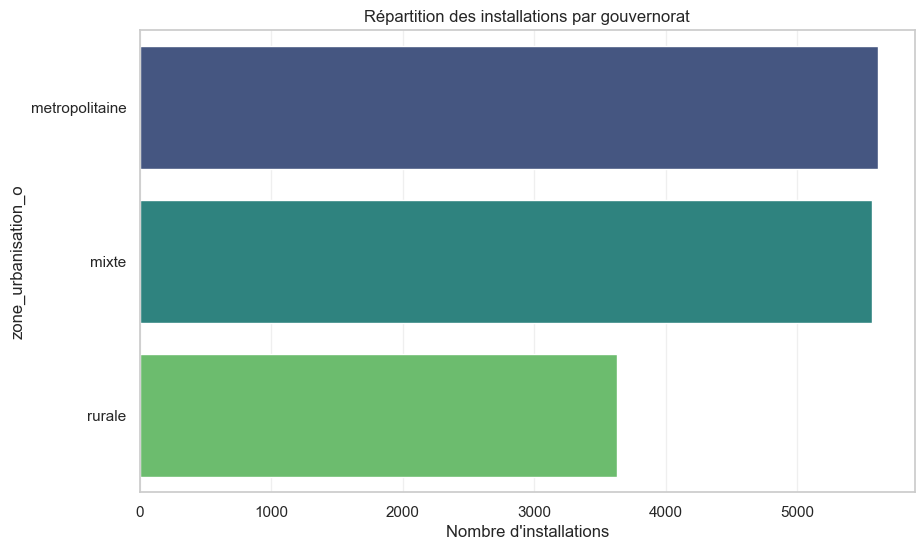

In [1272]:
geo = df["zone_urbanisation_o"].value_counts().reset_index()
geo.columns = ["zone_urbanisation_o", "Installations"]

geo = geo.sort_values("Installations", ascending=False)

plt.figure()
sns.barplot(data=geo, x="Installations", y="zone_urbanisation_o", palette="viridis")

plt.title("Répartition des installations par gouvernorat")
plt.xlabel("Nombre d'installations")
plt.ylabel("zone_urbanisation_o")
plt.show()

- On constate que Mahdia à le plus d'installation

In [1273]:
Nbre_installations_par_gouvernorat = df.groupby("zone_urbanisation_o")["zone_urbanisation_o"].count().sort_values(ascending=False)
Nbre_installations_par_gouvernorat

zone_urbanisation_o
metropolitaine    5614
mixte             5568
rurale            3626
Name: zone_urbanisation_o, dtype: int64

### 5.2 Distribution des installations selon le type de client :

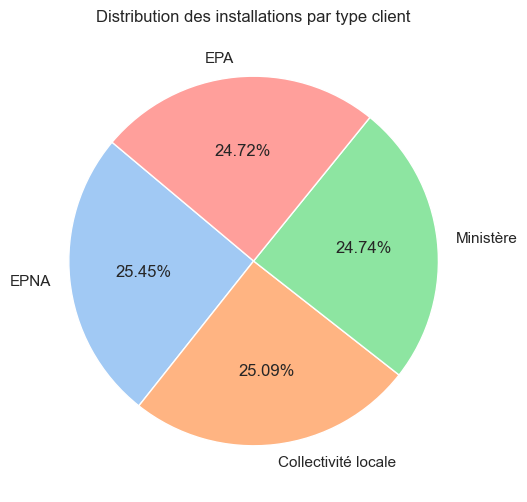

In [1274]:
client = df["Type_client_o"].value_counts()

plt.figure()
plt.pie(client, labels=client.index, autopct='%1.2f%%',
        startangle=140, colors=sns.color_palette("pastel"))

plt.title("Distribution des installations par type client")
plt.show()

- L'écart entre la distribution des installations entre les differents type de client est présque identique

### 5.3 répartition des installations par produit

- L'écart entre la distribution des installations entre les differents type de produits est présque identique

### 5.5 Distribution des installations en fonction de la taille du site

In [1275]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

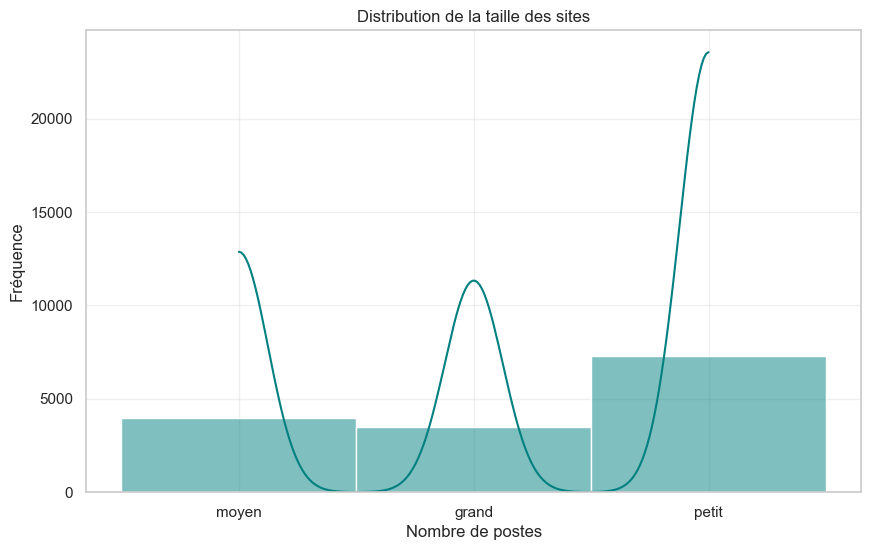

In [1276]:
sns.histplot(df["cat_taille_o"], bins=20, kde=True, color="teal")

plt.title("Distribution de la taille des sites")
plt.xlabel("Nombre de postes")
plt.ylabel("Fréquence")
plt.show()

* on constate que la plupart des sites qui ont entre 4 et 10 postes ont le plus d'installations

### 5.6 Distribution des versions de produits 

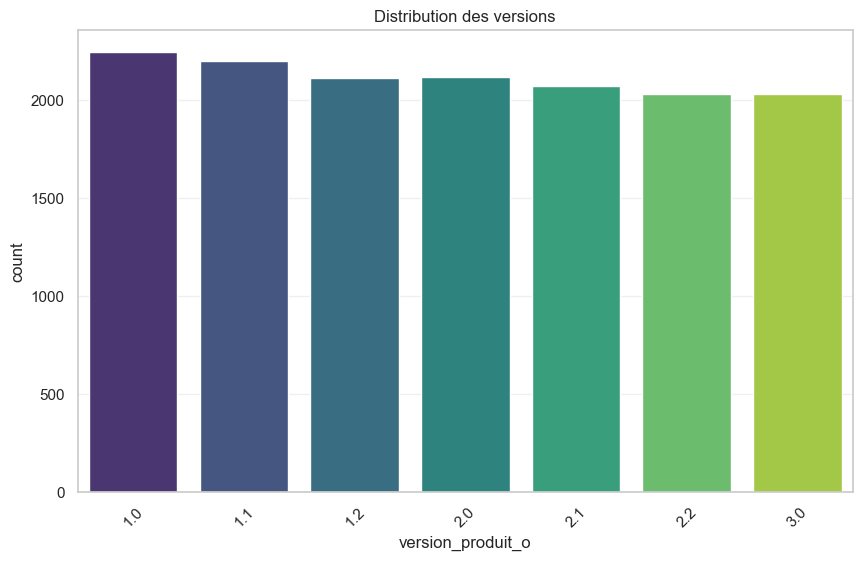

In [1277]:
sns.countplot(data=df, x="version_produit_o", palette="viridis")
plt.title("Distribution des versions")
plt.xticks(rotation=45)
plt.show()

- on trouve que les versions 1.0 et 1.1 sont les plus dominantes

In [1278]:
top_versions = df["version_produit_o"].value_counts().sort_values(ascending=False).head(2)
print(top_versions)
versions_obsoletes = df["version_produit_o"].value_counts().sort_values().head(2)
print(versions_obsoletes)

version_produit_o
1.0    2244
1.1    2200
Name: count, dtype: int64
version_produit_o
3.0    2028
2.2    2032
Name: count, dtype: int64


In [1279]:
"""# Assurer que year existe

exclude_cols = ["date_installation", "Remarques", "Id_Client"]

cat_cols = df.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    if col in exclude_cols or col == "year":
        continue

    # prendre les 5 modalités les plus fréquentes
    top_values = df[col].value_counts().nlargest(5).index
    df_filtered = df[df[col].isin(top_values)]

    evolution = (
        df_filtered
        .groupby(["year", col])
        .size()
        .reset_index(name="count")
    )

    fig = px.line(
        evolution,
        x="year",
        y="count",
        color=col,
        markers=True,
        title=f"Évolution par {col}"
    )

    fig.show()"""

'# Assurer que year existe\n\nexclude_cols = ["date_installation", "Remarques", "Id_Client"]\n\ncat_cols = df.select_dtypes(include=["object", "category"]).columns\n\nfor col in cat_cols:\n    if col in exclude_cols or col == "year":\n        continue\n\n    # prendre les 5 modalités les plus fréquentes\n    top_values = df[col].value_counts().nlargest(5).index\n    df_filtered = df[df[col].isin(top_values)]\n\n    evolution = (\n        df_filtered\n        .groupby(["year", col])\n        .size()\n        .reset_index(name="count")\n    )\n\n    fig = px.line(\n        evolution,\n        x="year",\n        y="count",\n        color=col,\n        markers=True,\n        title=f"Évolution par {col}"\n    )\n\n    fig.show()'

In [1280]:
"""num_cols = df2.select_dtypes(include=["int64", "float64"]).columns

for col in num_cols:
    if col == "year":
        continue

    evolution = (
        df2.groupby("year")[col]
        .mean()
        .reset_index()
    )

    fig = px.line(
        evolution,
        x="year",
        y=col,
        markers=True,
        title=f"Évolution moyenne de {col}"
    )

    fig.show()"""

'num_cols = df2.select_dtypes(include=["int64", "float64"]).columns\n\nfor col in num_cols:\n    if col == "year":\n        continue\n\n    evolution = (\n        df2.groupby("year")[col]\n        .mean()\n        .reset_index()\n    )\n\n    fig = px.line(\n        evolution,\n        x="year",\n        y=col,\n        markers=True,\n        title=f"Évolution moyenne de {col}"\n    )\n\n    fig.show()'

In [1281]:
import plotly.express as px

fig = px.pie(
    df,
    names="client_risque",
    title="Répartition des clients à risque",
    color="client_risque",
    color_discrete_map={0: "green", 1: "red"}
)

fig.show()


In [1282]:
fig = px.histogram(
    df,
    x="client_risque",
    nbins=2,
    title="Distribution du score de risque client",
    color="client_risque"
)

fig.show()


In [1283]:
version_risque = df.groupby("version_produit_o")["client_risque"].mean().reset_index()
version_risque.columns = ["version_produit_o", "taux_risque"]
version_max_risque = version_risque.sort_values("taux_risque", ascending=False).head(1)
print(version_max_risque)
fig = px.bar(
    version_risque,
    x="version_produit_o",
    y="taux_risque",
    title="Taux de risque par version produit",
    color="taux_risque",
    color_continuous_scale="Reds"
)

fig.show()


   version_produit_o  taux_risque
0                1.0     0.582888


In [1284]:
produit_risque = df.groupby("Nom_produit_o")["client_risque"].mean().reset_index()
produit_risque.columns = ["Nom_produit_o", "taux_risque"]
fig = px.bar(
    produit_risque,
    x="Nom_produit_o",
    y="taux_risque",
    title="Taux de risque par produit",
    color="taux_risque",
    color_continuous_scale="Reds"
)

fig.show()


In [1285]:
kpi_efficacite = {
    "taux_reussite_moyen": df["taux_reussite"].mean(),
    "temps_par_essai_moyen": df["temps_par_essai"].mean(),
    "efficacite_installation_moyenne": df["efficacite_installation"].mean()
}
kpi_efficacite

{'taux_reussite_moyen': np.float64(0.32152552674230145),
 'temps_par_essai_moyen': np.float64(29.637301908878083),
 'efficacite_installation_moyenne': np.float64(0.010469467932555777)}

In [1286]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

In [1287]:
df_grouped8 = df.groupby("temps_par_essai")["taux_reussite"].mean().reset_index()

fig = px.bar(
    df_grouped8,
    x="temps_par_essai",
    y="taux_reussite",
    title="Efficacité : Temps par essai vs Taux de réussite"
)

fig.show()

In [1288]:
kpi_complexite = {
    "complexite_moyenne_site": df["complexite_site"].mean(),
    "complexite_moyenne_installation": df["complexite_installation"].mean()
}

In [1289]:
fig = px.box(
    df,
    x="installation_reussie",
    y="complexite_installation",
    color="installation_reussie",
    title="Complexité vs Réussite"
)
fig.show()

In [1290]:
kpi_risque = {
    "taux_clients_risque": df["client_risque"].mean(),
}
kpi_risque

{'taux_clients_risque': np.float64(0.5654376012965965)}

In [1291]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

In [1292]:
risque_vs_reussite = df.groupby("client_risque")["installation_reussie_encoded"].mean().reset_index()

fig = px.bar(
    risque_vs_reussite,
    x="client_risque",
    y="installation_reussie_encoded",
    title="Impact du risque sur la réussite",
    color="client_risque"
)
fig.show()

In [1293]:
kpi_problemes = {
    "taux_pb_reseau": df["pb_reseau"].mean(),
    "taux_pb_config": df["pb_configuration"].mean(),
    "taux_pb_materiel": df["pb_materiel"].mean(),
    "taux_pb_version": df["pb_version"].mean()
}

In [1294]:
pb_cols = ["pb_reseau", "pb_configuration", "pb_materiel", "pb_version"]

pb_data = df[pb_cols].mean().reset_index()
pb_data.columns = ["type_probleme", "frequence"]

fig = px.bar(
    pb_data,
    x="type_probleme",
    y="frequence",
    title="Fréquence des types de problèmes",
    color="frequence"
)
fig.show()

In [1295]:
kpi_cat = df.groupby("cat_debit_o").agg({
    "installation_reussie_encoded": "mean",
    "client_satisfait_encoded": "mean",
    "client_risque": "mean"
}).reset_index()
kpi_cat

,cat_debit_o,installation_reussie_encoded,client_satisfait_encoded,client_risque
0,bon,0.582506,0.554793,0.433111
1,faible,0.069604,0.016740,0.995595
2,moyen,0.064740,0.018112,0.942197


In [1296]:
fig = px.bar(
    kpi_cat,
    x="cat_debit_o",
    y="installation_reussie_encoded",
    color="cat_debit_o",
    title="Impact du débit sur la réussite"
)
fig.show()

In [1297]:
kpi_weekend = df.groupby("weekend").agg({
    "installation_reussie_encoded": "mean",
    "Duree_installation_minutes": "mean",
    "client_satisfait_encoded": "mean"
}).reset_index()
kpi_weekend

,weekend,installation_reussie_encoded,Duree_installation_minutes,client_satisfait_encoded
0,0,0.457135,96.761609,0.421602
1,1,0.440528,97.668106,0.414149


In [1298]:
fig = px.bar(
    kpi_weekend,
    x="weekend",
    y="installation_reussie_encoded",
    title="Performance weekend vs semaine",
    color="weekend"
)
fig.show()

In [1299]:
kpi_upgrade = df.groupby("upgrade").agg({
    "installation_reussie_encoded": "mean",
    "client_risque": "mean",
    "Duree_installation_minutes": "mean"
}).reset_index()

In [1300]:
fig = px.bar(
    kpi_upgrade,
    x="upgrade",
    y="installation_reussie_encoded",
    color="upgrade",
    title="Impact des versions récentes (upgrade)"
)
fig.show()

In [1301]:
os_perf = df.groupby("Systeme_exploitation_poste").agg({
    "installation_reussie_encoded": "mean",
    "os_enc": "mean"
}).reset_index()

In [1302]:
fig = px.bar(
    os_perf,
    x="Systeme_exploitation_poste",
    y="installation_reussie_encoded",
    title="Performance par OS",
    color="installation_reussie_encoded"
)
fig.show()

In [1303]:
kpi_final = {
    "efficacite_globale": df["efficacite_installation"].mean(),
    "risque_global": df["client_risque"].mean(),
    "complexite_globale": df["complexite_installation"].mean(),
    "performance_reseau": df["pb_reseau"].mean()
}
kpi_final

{'efficacite_globale': np.float64(0.010469467932555777),
 'risque_global': np.float64(0.5654376012965965),
 'complexite_globale': np.float64(408.82212317666125),
 'performance_reseau': np.float64(0.10703673689897353)}

### 5.2 Extraction de colonnes 

### 5.3 cause:

In [1304]:
kpi_causes = {
    "pb_reseau": df[df["client_risque"] == 1]["pb_reseau"].mean(),
    "pb_configuration": df[df["client_risque"] == 1]["pb_configuration"].mean(),
    "pb_materiel": df[df["client_risque"] == 1]["pb_materiel"].mean(),
    "pb_version": df[df["client_risque"] == 1]["pb_version"].mean()
}
kpi_causes

{'pb_reseau': np.float64(0.18320793025200047),
 'pb_configuration': np.float64(0.17532545085393528),
 'pb_materiel': np.float64(0.2621521557386839),
 'pb_version': np.float64(0.45718380508778217)}

In [1305]:
df_grouped_duree = df.groupby("pb_reseau").agg({
    "Duree_installation_minutes": "mean"
}).reset_index()

fig = px.bar(
    df_grouped_duree,
    x="pb_reseau",
    y="Duree_installation_minutes",
    title="Impact problème réseau sur durée", 
    color="pb_reseau",
    color_discrete_map={0: "green", 1: "red"}
)
fig.show()

cause:

In [1306]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

In [1307]:
variables = [
    "zone_urbanisation_o", "cat_debit_o", "cat_taille_o",
    "Mode_installation_o", "Type_client_o", "Nom_produit_o", "upgrade",
    "weekend", "mois", "annee", "pb_reseau", "pb_configuration",
    "pb_materiel", "pb_version",
    "os_enc",
    "Duree_installation_minutes","version_produit_o","complexite_site",
    "complexite_installation","nombre_reclamations","weekend",
    "Nom_produit_o"
]

results = []

for var in variables:
    grouped = df.groupby(var)["client_risque"].mean().reset_index()
    
    grouped = grouped.rename(columns={
        var: "modalite",
        "client_risque": "taux_risque"
    })
    
    grouped["variable"] = var
    
    grouped["modalite"] = grouped["modalite"].astype(str)
    
    results.append(grouped)

df_risk_analysis = pd.concat(results, ignore_index=True)

df_risk_analysis.head(50)

,modalite,taux_risque,variable
0,metropolitaine,0.565372,zone_urbanisation_o
1,mixte,0.566810,zone_urbanisation_o
2,rurale,0.563431,zone_urbanisation_o
3,bon,0.433111,cat_debit_o
4,faible,0.995595,cat_debit_o
5,moyen,0.942197,cat_debit_o
6,grand,0.633077,cat_taille_o
7,moyen,0.533200,cat_taille_o
8,petit,0.550520,cat_taille_o
9,Technicien_sur_site,0.579892,Mode_installation_o


In [1308]:
df_risk_analysis = df_risk_analysis.copy()

# convertir toutes les colonnes interval en string
for col in df_risk_analysis.columns:
    if df_risk_analysis[col].dtype.name == "category":
        df_risk_analysis[col] = df_risk_analysis[col].astype(str)

In [1309]:
for var in df_risk_analysis["variable"].unique():
    
    df_var = (
        df_risk_analysis[df_risk_analysis["variable"] == var]
        .sort_values("taux_risque", ascending=False)
        .head(5)   # top 5 seulement
    )

    fig = px.bar(
        df_var,
        x="modalite",
        y="taux_risque",
        color="taux_risque",
        title=f"Top facteurs de risque - {var}"
    )

    fig.update_layout()

    fig.show()

In [1310]:
importance_var = (
    df_risk_analysis
    .groupby("variable")["taux_risque"]
    .agg(["max", "min"])
)

importance_var["impact"] = importance_var["max"] - importance_var["min"]

importance_var = importance_var.sort_values("impact", ascending=False)

In [1311]:
top5 = importance_var.head(5).reset_index()

In [1312]:
top5["label"] = "max=" + top5["max"].round(2).astype(str)

fig = px.bar(
    top5,
    x="impact",
    y="variable",
    orientation="h",
    text="label",
    color="impact",
    title="Top 5 facteurs influençant le risque client"
)

fig.show()

In [1313]:
df_grouped_version = df.groupby("version_produit_o")["client_risque"].mean().reset_index()

fig = px.bar(
    df_grouped_version,
    x="version_produit_o",
    y="client_risque",
    color="client_risque",
    title="Risque par version produit"
)
fig.show()

In [1314]:
df_grouped_produit = df.groupby("Nom_produit_o")["client_risque"].mean().reset_index()

fig = px.bar(
    df_grouped_produit,
    x="Nom_produit_o",
    y="client_risque",
    color="client_risque",
    title="Risque par produit"
)
fig.show()

### 5.4 Features selection

In [1315]:
"""df["mois"] = pd.to_datetime(df["mois"], format="%Y-%m")
df["mois_num"] = df["mois"].dt.month

var_a_effacer =["Nom_produit", 'date_installation', 'Gouvernorat',
       'Id_Client', 'Type_client', 'Systeme_exploitation_poste',
       'client_a_reclame', 'nombre_reclamations_client',
       'Remarques', 'Technicien_ID',"version_produit",
       'Debit_reseau_Mbps', 'Taille_site_postes', 'Mode_installation',
       'Version_precedente',"cat_version", "cat_taille", "cat_debit", "zone_urbanisation",
       'score_risque', 'year',
       'installation_reussie','client_satisfait','Tentative_installation_weekend',
       'version_produit_o',
       'Nom_produit_o', 'Type_client_o',
       'Mode_installation_o', 'cat_taille_o', 'cat_debit_o',
       'zone_urbanisation_o',"mois",]

df = df.drop(columns=var_a_effacer, errors='ignore')"""

'df["mois"] = pd.to_datetime(df["mois"], format="%Y-%m")\ndf["mois_num"] = df["mois"].dt.month\n\nvar_a_effacer =["Nom_produit", \'date_installation\', \'Gouvernorat\',\n       \'Id_Client\', \'Type_client\', \'Systeme_exploitation_poste\',\n       \'client_a_reclame\', \'nombre_reclamations_client\',\n       \'Remarques\', \'Technicien_ID\',"version_produit",\n       \'Debit_reseau_Mbps\', \'Taille_site_postes\', \'Mode_installation\',\n       \'Version_precedente\',"cat_version", "cat_taille", "cat_debit", "zone_urbanisation",\n       \'score_risque\', \'year\',\n       \'installation_reussie\',\'client_satisfait\',\'Tentative_installation_weekend\',\n       \'version_produit_o\',\n       \'Nom_produit_o\', \'Type_client_o\',\n       \'Mode_installation_o\', \'cat_taille_o\', \'cat_debit_o\',\n       \'zone_urbanisation_o\',"mois",]\n\ndf = df.drop(columns=var_a_effacer, errors=\'ignore\')'

In [1316]:
df.columns

Index(['version_produit', 'date_installation', 'Gouvernorat', 'Id_Client',
       'Systeme_exploitation_poste', 'installation_reussie',
       'nombre_essais_installation', 'client_a_reclame',
       'nombre_reclamations_client', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Duree_installation_minutes', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'score_risque', 'client_risque', 'nombre_reclamations', 'annee',
       'jour_semaine', 'mois', 'weekend', 'upgrade', 'os_enc', 'pb_reseau',
       'pb_configuration', 'pb_materiel', 'pb_version', 'Nom_produit_o',
       'Type_client_o', 'Mode_inst

In [1317]:
df["mois"] = pd.to_datetime(df["mois"], format="%Y-%m")
df["mois_num"] = df["mois"].dt.month

var_a_effacer =['date_installation', 'Gouvernorat', 'Id_Client', 'Remarques',
       'Technicien_ID', 'Debit_reseau_Mbps',
       'Taille_site_postes', 'Tentative_installation_weekend',
       'Version_precedente', 'installation_reussie',
       'client_satisfait', 'client_a_reclame',
       'version_produit_o','version_produit_encoded', 'taux_reussite', 'temps_par_essai',
       'efficacite_installation', 'complexite_site', 'complexite_installation',
       'nombre_reclamations', 'os_enc', 'Nom_produit_o',
       'Type_client_o', 'Mode_installation_o', 'cat_taille_o', 'cat_debit_o',
       'zone_urbanisation_o','score_risque',"mois"]

df = df.drop(columns=var_a_effacer, errors='ignore')

## 6. Modelisation

In [1318]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression, SelectKBest
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
# Modèles classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
# Modèles régression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

In [1319]:
# ── Feature Selection ─────────────────────────────────────────────────
def feature_selection(X, y, task="classification", k=15, seuil=0.01):

    if task == "classification":
        mi = mutual_info_classif(X, y, random_state=42)
    else:
        mi = mutual_info_regression(X, y, random_state=42)

    mi_df = pd.DataFrame({
        "feature": X.columns,
        "MI": mi
    }).sort_values("MI", ascending=False)

    # ── Affichage AVANT filtre ────────────────────────────────────────
    print(f"\n📊 Toutes les features ({len(mi_df)}) :")
    print(mi_df.to_string(index=False))

    # ── Filtre ────────────────────────────────────────────────────────
    retenues  = mi_df[mi_df["MI"] >= seuil].head(k)
    eliminées = mi_df[mi_df["MI"] <  seuil]

    # ── Affichage APRÈS filtre ────────────────────────────────────────
    print(f"\n✅ Features RETENUES (MI >= {seuil}) : {len(retenues)}")
    print(retenues.to_string(index=False))

    print(f"\n❌ Features ÉLIMINÉES (MI < {seuil}) : {len(eliminées)}")
    print(eliminées["feature"].tolist())

    features_retenues = retenues["feature"].tolist()
    return features_retenues, mi_df

# ── Standardisation ───────────────────────────────────────────────────
def standardiser(X_train, X_test, cols_continues):
    cols = [c for c in cols_continues if c in X_train.columns]
    scaler = StandardScaler()
    X_train = X_train.copy()
    X_test  = X_test.copy()
    X_train[cols] = scaler.fit_transform(X_train[cols])
    X_test[cols]  = scaler.transform(X_test[cols])
    return X_train, X_test, scaler

# ── Évaluation classification ─────────────────────────────────────────
def evaluer_classifieurs(modeles, X_train, X_test, y_train, y_test):
    resultats = []
    for nom, modele in modeles.items():
        modele.fit(X_train, y_train)
        y_pred  = modele.predict(X_test)
        y_proba = modele.predict_proba(X_test)[:, 1] if hasattr(modele, "predict_proba") else None

        cv = cross_val_score(modele, X_train, y_train,
                             cv=StratifiedKFold(5), scoring="f1").mean()
        resultats.append({
            "Modèle":    nom,
            "Accuracy":  accuracy_score(y_test, y_pred),
            "F1-Score":  f1_score(y_test, y_pred),
            "ROC-AUC":   roc_auc_score(y_test, y_proba) if y_proba is not None else None,
            "CV F1":     cv
        })
    return pd.DataFrame(resultats).sort_values("F1-Score", ascending=False)

# ── Évaluation régression ─────────────────────────────────────────────
def evaluer_regresseurs(modeles, X_train, X_test, y_train, y_test):
    resultats = []
    for nom, modele in modeles.items():
        modele.fit(X_train, y_train)
        y_pred = modele.predict(X_test)

        cv = cross_val_score(modele, X_train, y_train,
                             cv=KFold(5), scoring="r2").mean()
        resultats.append({
            "Modèle": nom,
            "R²":     r2_score(y_test, y_pred),
            "MAE":    mean_absolute_error(y_test, y_pred),
            "RMSE":   np.sqrt(mean_squared_error(y_test, y_pred)),
            "CV R²":  cv
        })
    return pd.DataFrame(resultats).sort_values("R²", ascending=False)

# ── Matrice de confusion ──────────────────────────────────────────────
def plot_confusion(modele, X_test, y_test, titre):
    cm = confusion_matrix(y_test, modele.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {titre}")
    plt.xlabel("Prédit"); plt.ylabel("Réel")
    plt.tight_layout(); plt.show()

def plot_resultats_regression(modele, X_test, y_test, titre):
    y_pred = modele.predict(X_test)
    residus = y_test - y_pred

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"Évaluation du modèle - {titre}", fontsize=14, fontweight="bold")

    # ── Plot 1 : Valeurs réelles vs prédites ─────────────────────────
    ax1 = axes[0, 0]
    ax1.scatter(y_test, y_pred, alpha=0.4, color="steelblue", edgecolors="white", s=30)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax1.plot([min_val, max_val], [min_val, max_val],
             color="red", linestyle="--", linewidth=2, label="Prédiction parfaite")
    ax1.set_xlabel("Valeurs réelles (minutes)")
    ax1.set_ylabel("Valeurs prédites (minutes)")
    ax1.set_title("Réel vs Prédit")
    ax1.legend()

    # ── Plot 2 : Distribution des résidus ─────────────────────────────
    ax2 = axes[0, 1]
    ax2.hist(residus, bins=40, color="coral", edgecolor="white", alpha=0.8)
    ax2.axvline(0, color="red", linestyle="--", linewidth=2, label="Résidu = 0")
    ax2.axvline(residus.mean(), color="navy", linestyle="-",
                linewidth=2, label=f"Moyenne = {residus.mean():.1f}")
    ax2.set_xlabel("Résidus (réel - prédit)")
    ax2.set_ylabel("Fréquence")
    ax2.set_title("Distribution des résidus")
    ax2.legend()

    # ── Plot 3 : Résidus vs Valeurs prédites ─────────────────────────
    ax3 = axes[1, 0]
    ax3.scatter(y_pred, residus, alpha=0.4, color="mediumseagreen", edgecolors="white", s=30)
    ax3.axhline(0, color="red", linestyle="--", linewidth=2)
    ax3.set_xlabel("Valeurs prédites (minutes)")
    ax3.set_ylabel("Résidus")
    ax3.set_title("Résidus vs Prédites")

    # ── Plot 4 : Métriques résumées ───────────────────────────────────
    ax4 = axes[1, 1]
    ax4.axis("off")
    r2   = r2_score(y_test, y_pred)
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    # Interprétation automatique
    if r2 >= 0.85:
        qualite = "Excellent"
    elif r2 >= 0.70:
        qualite = "Bon"
    elif r2 >= 0.50:
        qualite = "Moyen"
    else:
        qualite = "Faible"

    texte = (
        f"{'Métrique':<22} {'Valeur':>10}\n"
        f"{'─' * 34}\n"
        f"{'R²':<22} {r2:>10.3f}\n"
        f"{'MAE':<22} {mae:>9.2f} min\n"
        f"{'RMSE':<22} {rmse:>9.2f} min\n"
        f"{'Résidu moyen':<22} {residus.mean():>9.2f} min\n"
        f"{'Résidu std':<22} {residus.std():>9.2f} min\n"
        f"{'─' * 34}\n"
        f"{'Qualité':<22} {qualite:>10}\n"
    )
    ax4.text(0.1, 0.5, texte, transform=ax4.transAxes,
             fontsize=12, verticalalignment="center",
             fontfamily="monospace",
             bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.8))
    ax4.set_title("Métriques de performance")

    plt.tight_layout()
    plt.show()

    # ── Verdict final ─────────────────────────────────────────────────
    print(f"\n{'='*45}")
    print(f"  Modèle    : {titre}")
    print(f"  R²        : {r2:.3f}  → {qualite}")
    print(f"  MAE       : {mae:.2f} min  → erreur moyenne de {mae:.0f} minutes")
    print(f"  RMSE      : {rmse:.2f} min")
    print(f"{'='*45}")
    if mae <= 10:
        print("  ✅ Le modèle prédit avec une très bonne précision")
    elif mae <= 20:
        print("  ✅ Le modèle prédit correctement (erreur acceptable)")
    elif mae <= 30:
        print("  ⚠️  Erreur modérée, peut être amélioré")
    else:
        print("  ❌ Erreur trop élevée, revoir les features ou le modèle")




In [1320]:
from category_encoders import TargetEncoder

def target_encoding(X_train, X_test, df, target):

    y_train = df.loc[X_train.index, target]
    y_test  = df.loc[X_test.index, target]

    X_tr = X_train.copy()
    X_te = X_test.copy()

    # colonnes à encoder
    cols = ["Systeme_exploitation_poste", "version_produit"]

    encoder = TargetEncoder(cols=cols)

    X_tr[cols] = encoder.fit_transform(X_tr[cols], y_train)
    X_te[cols] = encoder.transform(X_te[cols])
    
    # supprimer anciennes colonnes
    X_tr = X_tr.drop(columns=["Systeme_exploitation_poste", "version_produit"], errors='ignore')
    X_te = X_te.drop(columns=["Systeme_exploitation_poste", "version_produit"], errors='ignore')

    return X_tr, X_te, y_train, y_test

In [1321]:
CLASSIFIEURS = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=42),
    "XGBoost":             XGBClassifier(eval_metric="logloss", random_state=42),
    "KNN":                 KNeighborsClassifier(),
    "SVM":                 SVC(probability=True, random_state=42),
}

REGRESSEURS = {
    "Linear Regression":   LinearRegression(),
    "Ridge":               Ridge(random_state=42),
    "Lasso":               Lasso(random_state=42),
    "Decision Tree":       DecisionTreeRegressor(random_state=42),
    "Random Forest":       RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting":   GradientBoostingRegressor(random_state=42),
    "XGBoost":             XGBRegressor(random_state=42),
}


In [1322]:
df.columns

Index(['version_produit', 'Systeme_exploitation_poste',
       'nombre_essais_installation', 'nombre_reclamations_client',
       'Duree_installation_minutes', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'client_risque', 'annee',
       'jour_semaine', 'weekend', 'upgrade', 'pb_reseau', 'pb_configuration',
       'pb_materiel', 'pb_version', 'Nom_produit_INSAF', 'Nom_produit_MADANIA',
       'Nom_produit_MAKATIB', 'Type_client_EPA', 'Type_client_EPNA',
       'Type_client_Ministère', 'Mode_installation_Télémaintenance',
       'cat_taille_moyen', 'cat_taille_petit', 'cat_debit_faible',
       'cat_debit_moyen', 'zone_urbanisation_mixte',
       'zone_urbanisation_rurale', 'mois_num'],
      dtype='object')

In [1323]:
targets = [
    "installation_reussie_encoded",
    "client_satisfait_encoded",
    "Duree_installation_minutes",
    "client_risque",
    "client_a_reclame_encoded" 
]

X = df.drop(columns=targets)

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

   MODÈLE 1 : client_risque

── Feature Selection ──

📊 Toutes les features (25) :
                               feature       MI
            nombre_essais_installation 0.241391
            nombre_reclamations_client 0.180245
                            pb_version 0.063318
                       cat_debit_moyen 0.060545
                             pb_reseau 0.050709
                      cat_debit_faible 0.048492
                   Nom_produit_MAKATIB 0.015038
               zone_urbanisation_mixte 0.012417
                   Nom_produit_MADANIA 0.011458
                 Type_client_Ministère 0.011452
                      pb_configuration 0.009749
                     Nom_produit_INSAF 0.006768
     Mode_installation_Télémaintenance 0.005788
Tentative_installation_weekend_encoded 0.004803
                      Type_client_EPNA 0.004358
                               upgrade 0.004121
              zone_urbanisation_rurale 0.003309
                           pb_materiel 0.002931
     

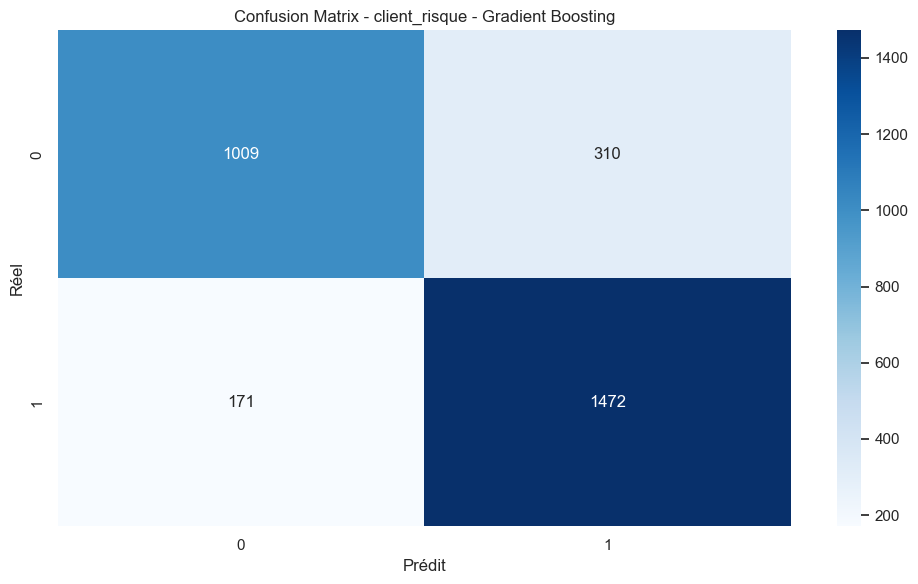

In [1324]:
print("=" * 60)
print("   MODÈLE 1 : client_risque")
print("=" * 60)

y1 = df["client_risque"]

X1_train, X1_test = X_train.copy(), X_test.copy()

# ── Encoding ──
X1_train, X1_test, y1_train, y1_test = target_encoding(
    X1_train, X1_test, df, "client_risque"
)

# ── Feature Selection ──
print("\n── Feature Selection ──")

features1, mi_df = feature_selection(
    X1_train, y1_train,
    task="classification",
    k=15
)

X1_train = X1_train[features1]
X1_test  = X1_test[features1]

# ── Model ──
resultats1 = evaluer_classifieurs(
    CLASSIFIEURS,
    X1_train, X1_test,
    y1_train, y1_test
)

print(resultats1)

best = resultats1.iloc[0]["Modèle"]
model1 = CLASSIFIEURS[best]

model1.fit(X1_train, y1_train)

print(classification_report(y1_test, model1.predict(X1_test)))
plot_confusion(model1, X1_test, y1_test, f"client_risque - {best}")

   MODÈLE 2 : installation_reussie

── Feature Selection ──

📊 Toutes les features (25) :
                               feature       MI
            nombre_essais_installation 0.501296
            nombre_reclamations_client 0.485614
                            pb_version 0.114047
                       cat_debit_moyen 0.074031
                      pb_configuration 0.042407
                             pb_reseau 0.036550
                           pb_materiel 0.029855
                      cat_debit_faible 0.024822
                      cat_taille_petit 0.024212
                   Nom_produit_MAKATIB 0.006782
               zone_urbanisation_mixte 0.004355
                               upgrade 0.002815
     Mode_installation_Télémaintenance 0.002779
                      cat_taille_moyen 0.002309
                              mois_num 0.002118
                          jour_semaine 0.001897
              zone_urbanisation_rurale 0.001678
                               weekend 0.00000

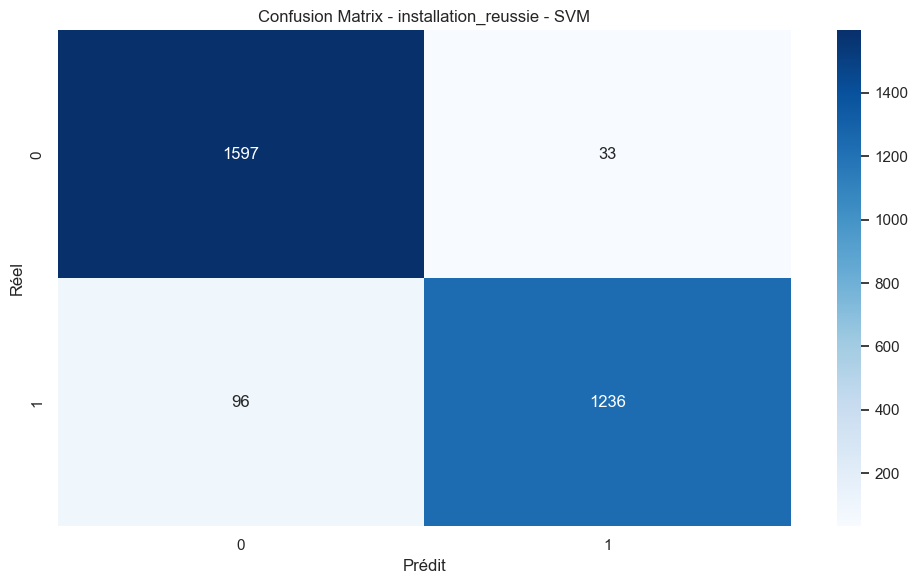

In [1325]:
print("=" * 60)
print("   MODÈLE 2 : installation_reussie")
print("=" * 60)

y2 = df["installation_reussie_encoded"]

X2_train, X2_test = X_train.copy(), X_test.copy()

X2_train, X2_test, y2_train, y2_test = target_encoding(
    X2_train, X2_test, df, "installation_reussie_encoded"
)

print("\n── Feature Selection ──")

features2, mi_df = feature_selection(
    X2_train, y2_train,
    task="classification",
    k=15
)

X2_train = X2_train[features2]
X2_test  = X2_test[features2]

resultats2 = evaluer_classifieurs(
    CLASSIFIEURS,
    X2_train, X2_test,
    y2_train, y2_test
)

print(resultats2)

best = resultats2.iloc[0]["Modèle"]
model2 = CLASSIFIEURS[best]

model2.fit(X2_train, y2_train)

print(classification_report(y2_test, model2.predict(X2_test)))
plot_confusion(model2, X2_test, y2_test, f"installation_reussie - {best}")

   MODÈLE 3 : client_satisfait

── Feature Selection ──

📊 Toutes les features (25) :
                               feature       MI
            nombre_essais_installation 0.574045
            nombre_reclamations_client 0.541495
                            pb_version 0.132562
                       cat_debit_moyen 0.088911
                      pb_configuration 0.053793
                             pb_reseau 0.050423
                      cat_debit_faible 0.038440
                           pb_materiel 0.032551
                      cat_taille_petit 0.028870
                   Nom_produit_MAKATIB 0.010273
                      cat_taille_moyen 0.005489
     Mode_installation_Télémaintenance 0.004952
               zone_urbanisation_mixte 0.004362
                               upgrade 0.002768
                              mois_num 0.001616
                   Nom_produit_MADANIA 0.000367
                          jour_semaine 0.000294
                               weekend 0.000000
  

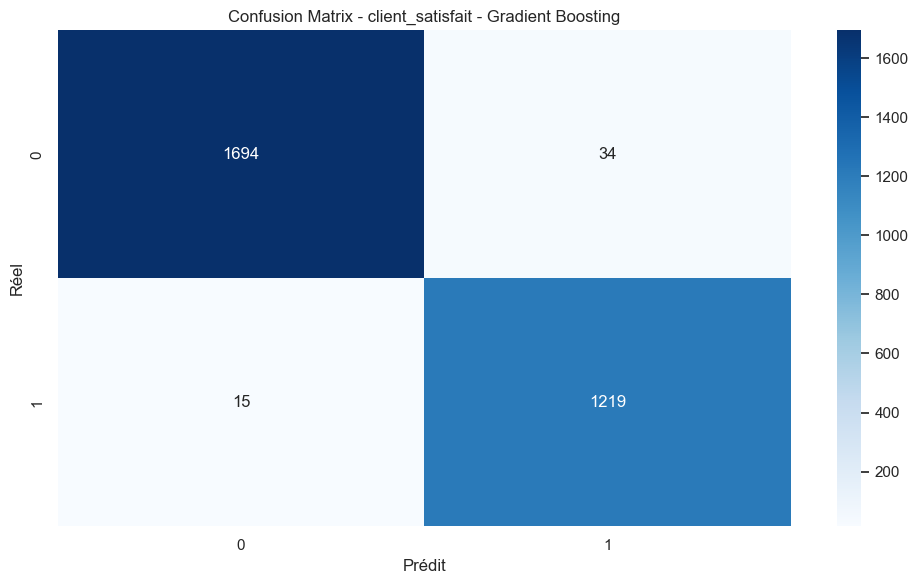

In [1326]:
print("=" * 60)
print("   MODÈLE 3 : client_satisfait")
print("=" * 60)

y3 = df["client_satisfait_encoded"]

X3_train, X3_test = X_train.copy(), X_test.copy()

X3_train, X3_test, y3_train, y3_test = target_encoding(
    X3_train, X3_test, df, "client_satisfait_encoded"
)

print("\n── Feature Selection ──")

features3, mi_df = feature_selection(
    X3_train, y3_train,
    task="classification",
    k=15
)

X3_train = X3_train[features3]
X3_test  = X3_test[features3]

resultats3 = evaluer_classifieurs(
    CLASSIFIEURS,
    X3_train, X3_test,
    y3_train, y3_test
)

print(resultats3)

best = resultats3.iloc[0]["Modèle"]
model3 = CLASSIFIEURS[best]

model3.fit(X3_train, y3_train)

print(classification_report(y3_test, model3.predict(X3_test)))
plot_confusion(model3, X3_test, y3_test, f"client_satisfait - {best}")

In [1327]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14808 entries, 0 to 15149
Data columns (total 32 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   version_produit                         14808 non-null  object
 1   Systeme_exploitation_poste              14808 non-null  object
 2   nombre_essais_installation              14808 non-null  int64 
 3   nombre_reclamations_client              14808 non-null  int64 
 4   Duree_installation_minutes              14808 non-null  int64 
 5   installation_reussie_encoded            14808 non-null  int64 
 6   client_satisfait_encoded                14808 non-null  int64 
 7   client_a_reclame_encoded                14808 non-null  int64 
 8   Tentative_installation_weekend_encoded  14808 non-null  int64 
 9   client_risque                           14808 non-null  int64 
 10  annee                                   14808 non-null  int32 
 11  jour_se

   MODÈLE 4 : durée installation

── Feature Selection ──

📊 Toutes les features (25) :
                               feature       MI
            nombre_essais_installation 0.713961
            nombre_reclamations_client 0.488529
                       cat_debit_moyen 0.137880
                            pb_version 0.095239
                             pb_reseau 0.088648
                      cat_debit_faible 0.068640
                      pb_configuration 0.045647
                      cat_taille_petit 0.044133
                 Type_client_Ministère 0.031193
                           pb_materiel 0.019759
     Mode_installation_Télémaintenance 0.017122
                      cat_taille_moyen 0.015273
                          jour_semaine 0.007467
                                 annee 0.002540
                               upgrade 0.002261
              zone_urbanisation_rurale 0.000623
                     Nom_produit_INSAF 0.000608
                               weekend 0.000000


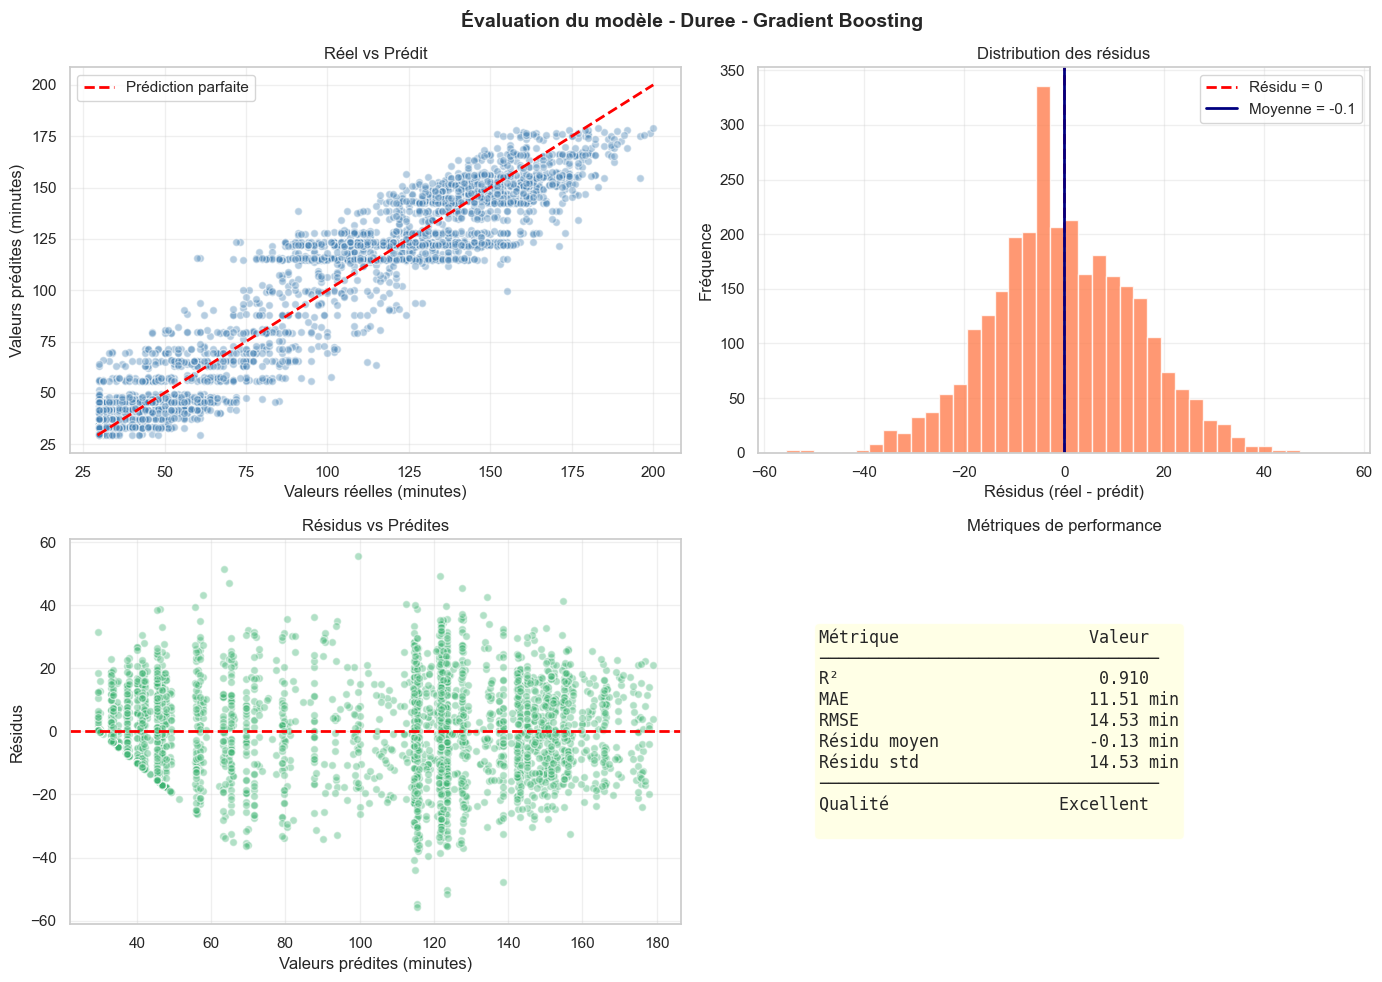


  Modèle    : Duree - Gradient Boosting
  R²        : 0.910  → Excellent
  MAE       : 11.51 min  → erreur moyenne de 12 minutes
  RMSE      : 14.53 min
  ✅ Le modèle prédit correctement (erreur acceptable)


In [1328]:
print("=" * 60)
print("   MODÈLE 4 : durée installation")
print("=" * 60)

y4 = df["Duree_installation_minutes"]

X4_train, X4_test = X_train.copy(), X_test.copy()

# ── Encoding ──
X4_train, X4_test, y4_train, y4_test = target_encoding(
    X4_train, X4_test, df, "Duree_installation_minutes"
)

print("\n── Feature Selection ──")

features4, mi_df = feature_selection(
    X4_train,
    y4_train,   # 🔥 FIX ICI
    task="regression",
    k=15
)

X4_train = X4_train[features4]
X4_test  = X4_test[features4]

resultats4 = evaluer_regresseurs(
    REGRESSEURS,
    X4_train, X4_test,
    y4_train,
    y4_test
)

print(resultats4)

best = resultats4.iloc[0]["Modèle"]
model4 = REGRESSEURS[best]

model4.fit(X4_train, y4_train)

plot_resultats_regression(
    model4,
    X4_test,
    y4_test,
    f"Duree - {best}"
)

   MODÈLE 5 : client_a_reclame

── Feature Selection ──

📊 Toutes les features (25) :
                               feature       MI
            nombre_essais_installation 0.577778
            nombre_reclamations_client 0.541175
                            pb_version 0.131171
                       cat_debit_moyen 0.088956
                      pb_configuration 0.054138
                             pb_reseau 0.050085
                      cat_debit_faible 0.037679
                           pb_materiel 0.031892
                      cat_taille_petit 0.028657
                   Nom_produit_MAKATIB 0.010579
                      cat_taille_moyen 0.006160
     Mode_installation_Télémaintenance 0.005716
               zone_urbanisation_mixte 0.005130
                               upgrade 0.002728
                              mois_num 0.002470
                                 annee 0.000000
                          jour_semaine 0.000000
                               weekend 0.000000
Te

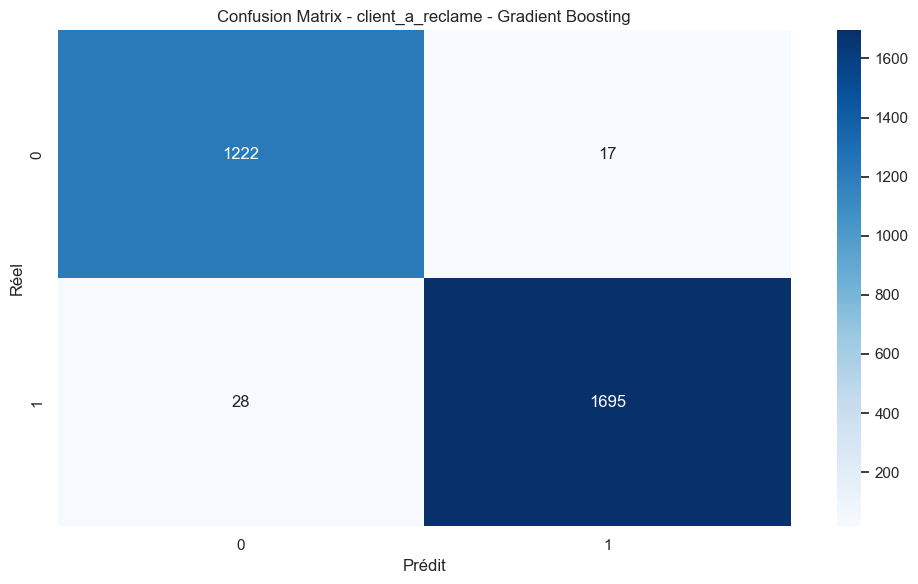

In [1329]:
print("=" * 60)
print("   MODÈLE 5 : client_a_reclame")
print("=" * 60)

y3 = df["client_a_reclame_encoded"]

X3_train, X3_test = X_train.copy(), X_test.copy()

X3_train, X3_test, y3_train, y3_test = target_encoding(
    X3_train, X3_test, df, "client_a_reclame_encoded"
)

print("\n── Feature Selection ──")

features3, mi_df = feature_selection(
    X3_train, y3_train,
    task="classification",
    k=15
)

X3_train = X3_train[features3]
X3_test  = X3_test[features3]

resultats3 = evaluer_classifieurs(
    CLASSIFIEURS,
    X3_train, X3_test,
    y3_train, y3_test
)

print(resultats3)

best = resultats3.iloc[0]["Modèle"]
model3 = CLASSIFIEURS[best]

model3.fit(X3_train, y3_train)

print(classification_report(y3_test, model3.predict(X3_test)))
plot_confusion(model3, X3_test, y3_test, f"client_a_reclame - {best}")

In [1330]:
print("\n" + "=" * 60)
print("   SYNTHÈSE FINALE")
print("=" * 60)

synthese = pd.DataFrame([
    {"Cible": "client_risque",              "Type": "Classification",
     "Meilleur modèle": meilleur1_nom,
     "F1": resultats1.iloc[0]["F1-Score"],
     "ROC-AUC": resultats1.iloc[0]["ROC-AUC"]},

    {"Cible": "installation_reussie",       "Type": "Classification",
     "Meilleur modèle": meilleur2_nom,
     "F1": resultats2.iloc[0]["F1-Score"],
     "ROC-AUC": resultats2.iloc[0]["ROC-AUC"]},

    {"Cible": "client_satisfait",           "Type": "Classification",
     "Meilleur modèle": meilleur3_nom,
     "F1": resultats3.iloc[0]["F1-Score"],
     "ROC-AUC": resultats3.iloc[0]["ROC-AUC"]},

    {"Cible": "Duree_installation_minutes", "Type": "Régression",
     "Meilleur modèle": meilleur4_nom,
     "R²": resultats4.iloc[0]["R²"],
     "RMSE": resultats4.iloc[0]["RMSE"]},
])

print(synthese.to_string(index=False))


   SYNTHÈSE FINALE
                     Cible           Type   Meilleur modèle       F1  ROC-AUC       R²      RMSE
             client_risque Classification Gradient Boosting 0.859562 0.928322      NaN       NaN
      installation_reussie Classification           XGBoost 0.950404 0.969260      NaN       NaN
          client_satisfait Classification Gradient Boosting 0.986900 0.996629      NaN       NaN
Duree_installation_minutes     Régression Gradient Boosting      NaN      NaN 0.910098 14.533031


In [1331]:
"""from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import recall_score

# ── Fonction de rééquilibrage ─────────────────────────────────────────
def reequilibrer(X_train, y_train, strategie="smote"):
    print(f"\nAvant rééquilibrage : {dict(y_train.value_counts())}")
    if strategie == "smote":
        sampler = SMOTE(random_state=42)
        X_res, y_res = sampler.fit_resample(X_train, y_train)
    elif strategie == "under":
        sampler = RandomUnderSampler(random_state=42)
        X_res, y_res = sampler.fit_resample(X_train, y_train)
    elif strategie == "combine":
        over  = SMOTE(sampling_strategy=0.5, random_state=42)
        under = RandomUnderSampler(sampling_strategy=0.8, random_state=42)
        X_res, y_res = over.fit_resample(X_train, y_train)
        X_res, y_res = under.fit_resample(X_res, y_res)
    print(f"Après rééquilibrage  : {dict(pd.Series(y_res).value_counts())}")
    return X_res, y_res

# ── Évaluation adaptée au déséquilibre ───────────────────────────────
def evaluer_desequilibre(modeles, X_train, X_test, y_train, y_test):
    resultats = []
    for nom, modele in modeles.items():
        modele.fit(X_train, y_train)
        y_pred  = modele.predict(X_test)
        y_proba = modele.predict_proba(X_test)[:, 1] \
                  if hasattr(modele, "predict_proba") else None

        cv = cross_val_score(
            modele, X_train, y_train,
            cv=StratifiedKFold(5, shuffle=True, random_state=42),
            scoring="f1_macro"
        ).mean()

        resultats.append({
            "Modèle":          nom,
            "Accuracy":        accuracy_score(y_test, y_pred),
            "F1-macro":        f1_score(y_test, y_pred, average="macro"),
            "F1-minorité":     f1_score(y_test, y_pred, pos_label=1),
            "Recall-minorité": recall_score(y_test, y_pred, pos_label=1)
                               if 1 in y_pred else 0,
            "ROC-AUC":         roc_auc_score(y_test, y_proba)
                               if y_proba is not None else None,
            "CV F1-macro":     cv
        })
    return pd.DataFrame(resultats).sort_values("F1-macro", ascending=False)

# ── Classifieurs équilibrés ───────────────────────────────────────────
def get_classifieurs_balances(scale_pos_weight=10):
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=42),
        "Decision Tree": DecisionTreeClassifier(
            class_weight="balanced", random_state=42),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, class_weight="balanced", random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "XGBoost": XGBClassifier(
            eval_metric="logloss", random_state=42,
            scale_pos_weight=scale_pos_weight),
        "KNN": KNeighborsClassifier(),
        "SVM": SVC(probability=True, class_weight="balanced", random_state=42),
    }

# ═════════════════════════════════════════════════════════════
#    MODÈLE 1 : client_risque
# ═════════════════════════════════════════════════════════════
print("=" * 60)
print("   MODÈLE 1 : client_risque (Classification)")
print("=" * 60)

X1_raw = df[[
    "nombre_essais_installation", "Duree_installation_minutes",
    "annee", "mois_num", "weekend", "upgrade", "os_enc",
    "version_produit_encoded", "pb_reseau", "pb_configuration",
    "pb_materiel", "pb_version",
    "Nom_produit_INSAF", "Nom_produit_MADANIA", "Nom_produit_MAKATIB",
    "Type_client_EPA", "Type_client_EPNA", "Type_client_Ministère",
    "Mode_installation_Télémaintenance",
    "cat_taille_moyen", "cat_taille_petit",
    "cat_debit_faible", "cat_debit_moyen",
    "zone_urbanisation_mixte", "zone_urbanisation_rurale"
]]
y1 = df["client_risque"]

print("\n── Feature Selection ──")
features1, _ = feature_selection(X1_raw, y1, task="classification", k=15, seuil=0.005)
X1 = X1_raw[features1]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1)

X1_train, X1_test, scaler1 = standardiser(X1_train, X1_test, COLS_CONTINUES)

X1_train_res, y1_train_res = reequilibrer(X1_train, y1_train, strategie="smote")

ratio1 = (y1_train == 0).sum() / (y1_train == 1).sum()
clf1   = get_classifieurs_balances(scale_pos_weight=ratio1)

print("\n── Résultats des modèles ──")
resultats1 = evaluer_desequilibre(clf1, X1_train_res, X1_test, y1_train_res, y1_test)
print(resultats1.to_string(index=False))

meilleur1_nom = resultats1.iloc[0]["Modèle"]
meilleur1     = clf1[meilleur1_nom]
meilleur1.fit(X1_train_res, y1_train_res)
print(f"\n🏆 Meilleur modèle : {meilleur1_nom}")
print(classification_report(y1_test, meilleur1.predict(X1_test)))
plot_confusion(meilleur1, X1_test, y1_test, f"client_risque - {meilleur1_nom}")

# ═════════════════════════════════════════════════════════════
#    MODÈLE 2 : installation_reussie
# ═════════════════════════════════════════════════════════════
print("=" * 60)
print("   MODÈLE 2 : installation_reussie (Classification)")
print("=" * 60)

X2_raw = df[[
    "nombre_essais_installation", "Duree_installation_minutes",
    "annee", "mois_num", "weekend", "upgrade", "os_enc",
    "version_produit_encoded", "pb_reseau", "pb_configuration",
    "pb_materiel", "pb_version",
    "Nom_produit_INSAF", "Nom_produit_MADANIA", "Nom_produit_MAKATIB",
    "Type_client_EPA", "Type_client_EPNA", "Type_client_Ministère",
    "Mode_installation_Télémaintenance",
    "cat_taille_moyen", "cat_taille_petit",
    "cat_debit_faible", "cat_debit_moyen",
    "zone_urbanisation_mixte", "zone_urbanisation_rurale"
]]
y2 = df["installation_reussie_encoded"]

print("\n── Feature Selection ──")
features2, _ = feature_selection(X2_raw, y2, task="classification", k=10, seuil=0.0)
X2 = X2_raw[features2]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2)

X2_train, X2_test, scaler2 = standardiser(X2_train, X2_test, COLS_CONTINUES)

X2_train_res, y2_train_res = reequilibrer(X2_train, y2_train, strategie="combine")

ratio2 = (y2_train == 0).sum() / (y2_train == 1).sum()
clf2   = get_classifieurs_balances(scale_pos_weight=ratio2)

print("\n── Résultats des modèles ──")
resultats2 = evaluer_desequilibre(clf2, X2_train_res, X2_test, y2_train_res, y2_test)
print(resultats2.to_string(index=False))

meilleur2_nom = resultats2.iloc[0]["Modèle"]
meilleur2     = clf2[meilleur2_nom]
meilleur2.fit(X2_train_res, y2_train_res)
print(f"\n🏆 Meilleur modèle : {meilleur2_nom}")
print(classification_report(y2_test, meilleur2.predict(X2_test)))
plot_confusion(meilleur2, X2_test, y2_test, f"installation_reussie - {meilleur2_nom}")

# ═════════════════════════════════════════════════════════════
#    MODÈLE 3 : client_satisfait
# ═════════════════════════════════════════════════════════════
print("=" * 60)
print("   MODÈLE 3 : client_satisfait (Classification)")
print("=" * 60)

X3_raw = df[[
    "nombre_essais_installation", "Duree_installation_minutes",
    "annee", "mois_num", "weekend", "upgrade", "os_enc",
    "version_produit_encoded", "pb_reseau", "pb_configuration",
    "pb_materiel", "pb_version",
    "Nom_produit_INSAF", "Nom_produit_MADANIA", "Nom_produit_MAKATIB",
    "Type_client_EPA", "Type_client_EPNA", "Type_client_Ministère",
    "Mode_installation_Télémaintenance",
    "cat_taille_moyen", "cat_taille_petit",
    "cat_debit_faible", "cat_debit_moyen",
    "zone_urbanisation_mixte", "zone_urbanisation_rurale"
]]
y3 = df["client_satisfait_encoded"]

print("\n── Feature Selection ──")
features3, _ = feature_selection(X3_raw, y3, task="classification", k=10, seuil=0.0)
X3 = X3_raw[features3]

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3)

X3_train, X3_test, scaler3 = standardiser(X3_train, X3_test, COLS_CONTINUES)

X3_train_res, y3_train_res = reequilibrer(X3_train, y3_train, strategie="combine")

ratio3 = (y3_train == 0).sum() / (y3_train == 1).sum()
clf3   = get_classifieurs_balances(scale_pos_weight=ratio3)

print("\n── Résultats des modèles ──")
resultats3 = evaluer_desequilibre(clf3, X3_train_res, X3_test, y3_train_res, y3_test)
print(resultats3.to_string(index=False))

meilleur3_nom = resultats3.iloc[0]["Modèle"]
meilleur3     = clf3[meilleur3_nom]
meilleur3.fit(X3_train_res, y3_train_res)
print(f"\n🏆 Meilleur modèle : {meilleur3_nom}")
print(classification_report(y3_test, meilleur3.predict(X3_test)))
plot_confusion(meilleur3, X3_test, y3_test, f"client_satisfait - {meilleur3_nom}")

# ═════════════════════════════════════════════════════════════
#    MODÈLE 4 : Duree_installation_minutes (Régression)
# ═════════════════════════════════════════════════════════════
print("=" * 60)
print("   MODÈLE 4 : Duree_installation_minutes (Régression)")
print("=" * 60)

X4_raw = df[[
    "nombre_essais_installation",
    "annee", "mois_num", "weekend", "upgrade", "os_enc",
    "version_produit_encoded", "pb_reseau", "pb_configuration",
    "pb_materiel", "pb_version",
    "Nom_produit_INSAF", "Nom_produit_MADANIA", "Nom_produit_MAKATIB",
    "Type_client_EPA", "Type_client_EPNA", "Type_client_Ministère",
    "Mode_installation_Télémaintenance",
    "cat_taille_moyen", "cat_taille_petit",
    "cat_debit_faible", "cat_debit_moyen",
    "zone_urbanisation_mixte", "zone_urbanisation_rurale"
]]
y4 = df["Duree_installation_minutes"]

print("\n── Feature Selection ──")
features4, _ = feature_selection(X4_raw, y4, task="regression", k=10, seuil=0.0)
X4 = X4_raw[features4]

X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.2, random_state=42)

cols_reg = [c for c in COLS_CONTINUES if c != "Duree_installation_minutes"]
X4_train, X4_test, scaler4 = standardiser(X4_train, X4_test, cols_reg)

print("\n── Résultats des modèles ──")
resultats4 = evaluer_regresseurs(REGRESSEURS, X4_train, X4_test, y4_train, y4_test)
print(resultats4.to_string(index=False))

meilleur4_nom = resultats4.iloc[0]["Modèle"]
meilleur4     = REGRESSEURS[meilleur4_nom]
meilleur4.fit(X4_train, y4_train)
print(f"\n🏆 Meilleur modèle : {meilleur4_nom}")
plot_resultats_regression(
    meilleur4, X4_test, y4_test, f"Duree_installation_minutes - {meilleur4_nom}")

# ═════════════════════════════════════════════════════════════
#    SYNTHÈSE FINALE
# ═════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("   SYNTHÈSE FINALE")
print("=" * 60)

synthese = pd.DataFrame([
    {"Cible": "client_risque",
     "Type": "Classification",
     "Meilleur modèle": meilleur1_nom,
     "F1-macro":  resultats1.iloc[0]["F1-macro"],
     "ROC-AUC":   resultats1.iloc[0]["ROC-AUC"]},

    {"Cible": "installation_reussie",
     "Type": "Classification",
     "Meilleur modèle": meilleur2_nom,
     "F1-macro":  resultats2.iloc[0]["F1-macro"],
     "ROC-AUC":   resultats2.iloc[0]["ROC-AUC"]},

    {"Cible": "client_satisfait",
     "Type": "Classification",
     "Meilleur modèle": meilleur3_nom,
     "F1-macro":  resultats3.iloc[0]["F1-macro"],
     "ROC-AUC":   resultats3.iloc[0]["ROC-AUC"]},

    {"Cible": "Duree_installation_minutes",
     "Type": "Régression",
     "Meilleur modèle": meilleur4_nom,
     "R²":   resultats4.iloc[0]["R²"],
     "RMSE": resultats4.iloc[0]["RMSE"]},
])

print(synthese.to_string(index=False))"""

'from imblearn.over_sampling import SMOTE\nfrom imblearn.under_sampling import RandomUnderSampler\nfrom sklearn.metrics import recall_score\n\n# ── Fonction de rééquilibrage ─────────────────────────────────────────\ndef reequilibrer(X_train, y_train, strategie="smote"):\n    print(f"\nAvant rééquilibrage : {dict(y_train.value_counts())}")\n    if strategie == "smote":\n        sampler = SMOTE(random_state=42)\n        X_res, y_res = sampler.fit_resample(X_train, y_train)\n    elif strategie == "under":\n        sampler = RandomUnderSampler(random_state=42)\n        X_res, y_res = sampler.fit_resample(X_train, y_train)\n    elif strategie == "combine":\n        over  = SMOTE(sampling_strategy=0.5, random_state=42)\n        under = RandomUnderSampler(sampling_strategy=0.8, random_state=42)\n        X_res, y_res = over.fit_resample(X_train, y_train)\n        X_res, y_res = under.fit_resample(X_res, y_res)\n    print(f"Après rééquilibrage  : {dict(pd.Series(y_res).value_counts())}")\n    